# 🚀 ITSM Ticket Similarity - Real ServiceNow Data Training (V2 + LoRA/PEFT)

**Model:** `sentence-transformers/all-mpnet-base-v2` (768-dim embeddings) **+ LoRA adapters**  
**Data:** Real ServiceNow incidents (Mar 2024 → Sep 2025, ~30K+ tickets)  
**Use Case:** Find similar tickets, detect duplicates, assist routing

## 🆕 LoRA/PEFT Improvements (This Version)

### 1. **Parameter-Efficient Fine-Tuning (LoRA)**
- **90%+ parameter reduction**: Only ~3-5M trainable params vs ~30-50M full fine-tune
- **LoRA rank**: 16, alpha: 32, targeting attention Q/V projections
- **Faster training**: Reduced memory footprint and faster gradient updates
- **Better generalization**: Less overfitting on domain-specific data
- **Learning rate**: 1e-4 (optimized for LoRA vs 2e-5 for full fine-tune)

### 2. **Multi-Loss Training**
- **MultipleNegativesRankingLoss (90%)**: Primary loss for ranking/similarity ordering
  - Leverages in-batch negatives for efficient contrastive learning
  - Optimizes embedding space for relative similarity
- **CosineSimilarityLoss (10%)**: Auxiliary loss for calibration
  - Improves absolute similarity score calibration
  - Better threshold-based binary classification (F1, precision, recall)
  - Addresses the "similarity score calibration" gap

**Why this combination?**
- MNRL excels at ranking but may not calibrate absolute scores well
- CosineSimilarity provides calibrated similarity values for thresholding
- Together: Best of both worlds for ranking + classification tasks

## V2 Base Improvements (Inherited)
1. **Harder negative mining** — Increased hard_neg_ratio (35%→45%), stricter TF-IDF threshold (0.20→0.12)
2. **Curriculum learning** — Progressive difficulty: easy pairs first, hard pairs later
3. **Borderline test set** — New "adversarial v2" with TF-IDF 0.25-0.35 (ambiguous cases)
4. **Error analysis** — Systematic failure pattern detection
5. **Cross-validated threshold** — 5-fold CV for robust production threshold

## Key Differences from Dummy Data Pipeline
1. **No Short Description** — Real data only has `Description` field
2. **Rich vocabulary** — 10K+ unique terms vs 111 in dummy data
3. **Realistic metrics expected** — ROC-AUC 0.85-0.90, Spearman 0.65-0.75
4. **No Resolution notes in training text** — Avoids data leakage for new tickets

## Expected Benefits
- **Training efficiency**: 2-3x faster with LoRA (fewer params to update)
- **Memory savings**: Lower GPU memory usage enables larger batch sizes
- **Performance**: Comparable or better than full fine-tune due to regularization
- **Threshold calibration**: Improved binary classification metrics (F1, precision/recall)

# 1. Environment Setup

## 📋 Quick Configuration Summary

| Component | Setting | Rationale |
|-----------|---------|-----------|
| **LoRA Rank** | 16 | Balanced capacity (8=low, 32=high) |
| **LoRA Alpha** | 32 | Standard scaling (2×rank) |
| **Target Modules** | q_proj, v_proj | Attention query/value projections |
| **Learning Rate** | 1e-4 | Lower than full fine-tune (2e-5) |
| **MNRL Weight** | 0.9 | Primary ranking loss |
| **Cosine Weight** | 0.1 | Auxiliary calibration |
| **Batch Size** | 16 (8 on MPS) | Auto-adjusted for device |
| **Epochs** | 4 | 2 phases × 2 epochs each |

**Key Metrics to Watch:**
- **Trainable params**: Should be ~3-5M (vs ~30-50M baseline)
- **Spearman correlation**: Target > 0.75 (current V2 best: 0.7516)
- **ROC-AUC**: Target > 0.93 (current V2 best: 0.9369)
- **F1 @ optimal threshold**: Target > 0.84 (current V2 best: 0.8442)

In [1]:
import os, sys, subprocess
from pathlib import Path

# Environment variables to suppress warnings
os.environ['WANDB_DISABLED'] = 'true'
os.environ['WANDB_MODE'] = 'offline'
os.environ['WANDB_SILENT'] = 'true'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Install required packages
def ensure_packages():
    try:
        import importlib.metadata as importlib_metadata
    except ImportError:
        import importlib_metadata
    
    required = {
        'sentence-transformers': 'sentence-transformers>=2.2.2',
        'torch': 'torch',
        'scikit-learn': 'scikit-learn>=1.3.0',
        'pandas': 'pandas',
        'numpy': 'numpy>=1.24.0',
        'tqdm': 'tqdm',
        'matplotlib': 'matplotlib',
        'seaborn': 'seaborn',
        'peft': 'peft>=0.4.0',  # LoRA/PEFT support
        'transformers': 'transformers>=4.30.0',# Compatible with PEFT
        'datasets': 'datasets>=2.13.1',
        'importlib_metadata': 'importlib-metadata; python_version<"3.11"',
    }
    
    missing = []
    for name, spec in required.items():
        try:
            importlib_metadata.version(name)
        except importlib_metadata.PackageNotFoundError:
            missing.append(spec)
    
    if missing:
        print(f'[INSTALL] Installing: {", ".join(missing)}')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
    else:
        print('[OK] All packages installed')

ensure_packages()

[INSTALL] Installing: importlib-metadata; python_version<"3.11"


# 2. Configuration

In [2]:
import random
import numpy as np
import torch
import logging

# Simple logging
def log(msg, level=logging.INFO):
    print(msg)

# --- CONFIGURATION (V6.0 - Nomic Base, ResNotes Distant Supervision) ---
# V6.0 changes vs V5.3:
#   Base model swapped: all-mpnet-base-v2 → nomic-ai/nomic-embed-text-v1.5
#   Motivation: Nomic achieved Spearman=0.4476 zero-shot on the grounded
#               semantic benchmark vs 0.2920 for MPNet — highest ceiling.
#   LoRA target: changed to 'Wqkv' (Nomic's fused QKV projection);
#                'query'/'key'/'value' kept as fallback.
#   New train_pairs_path so pairs are regenerated fresh (new model tokenizer).
#   Everything else (curriculum, CosineSimilarityLoss, best-state tracking) unchanged.
CONFIG = {
    # Model
    'model_name': 'nomic-ai/nomic-embed-text-v1.5',
    'trust_remote_code': True,         # Required for Nomic custom bert architecture
    'output_dir': 'models/real_servicenow_finetuned_nomic_lora',

    # Data - V6.0: resnotes_curriculum pairs with TF-IDF cosine of Resolution notes as labels
    'use_pre_generated_pairs': True,   # Generate once, reuse across phases
    'train_pairs_path': 'data_new/resnotes_curriculum_training_pairs_v6.json',  # V6: resnotes distant supervision
    'eval_pairs_path':  'data_new/benchmark_v4_semantic_resnotes.json',
    'source_data': 'data_new\\SNow_incident_ticket_data.csv',

    # LoRA/PEFT Configuration
    'use_lora': True,
    'lora_r': 16,
    'lora_alpha': 32,
    'lora_dropout': 0.1,
    'lora_target_modules': ['Wqkv', 'query', 'key', 'value'],  # Wqkv = Nomic fused QKV; fallbacks for other archs

    # Loss Function — pure CosineSimilarityLoss (float labels 0.0-1.0, ideal for V6 continuous similarity)
    'use_multi_loss': False,
    'loss_type': 'cosine',
    'mnrl_weight': 0.7,
    'cosine_weight': 0.3,
    'mnrl_scale': 15.0,

    # Training hyperparameters
    'epochs': 12,
    'batch_size': 32,
    'lr': 2e-5,
    'max_seq_length': 256,
    'warmup_ratio': 0.1,

    # Curriculum Learning
    'use_curriculum': True,
    'epochs_per_phase': 4,

    # Semantic hard negative mining (disabled)
    'use_semantic_hard_negatives': False,
    'semantic_hard_negative_fraction': 0.2,
    'semantic_min_similarity': None,
    'semantic_model_name': 'sentence-transformers/all-mpnet-base-v2',
    'semantic_batch_size': 64,
    'semantic_device': None,

    # Data splits
    'eval_split': 0.15,
    'holdout_split': 0.10,
    'min_text_length': 25,

    # Pair generation (LEGACY)
    'num_pairs': 50000,
    'pos_ratio': 0.30,

    # CV threshold selection
    'threshold_cv_folds': 5,

    # Reproducibility
    'seed': 42,

    # MNRL Positive-Only Mode
    'use_mnrl_positive_only': False,
    'train_pairs_path_mnrl': 'data_new/group_based_positive_only_pairs_mnrl_v1.json',
}

# Set seeds
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])

log("="*70)
log("CONFIGURATION (V6.0 - Nomic - ResNotes Distant Supervision)")
log("="*70)
log(f"Model: {CONFIG['model_name']}  (trust_remote_code={CONFIG['trust_remote_code']})")
log(f"Output: {CONFIG['output_dir']}")
log(f"\nData (V6.0 — ResNotes Distant Supervision):")
log(f"  Train pairs: {CONFIG['train_pairs_path']}")
log(f"  Eval pairs:  {CONFIG['eval_pairs_path']}")
log(f"\nLoss (pure CosineSimilarityLoss):")
log(f"  use_multi_loss: {CONFIG['use_multi_loss']} (MNRL disabled)")
log(f"  loss_type: {CONFIG['loss_type']}")
log(f"\nTraining:")
log(f"  Total epochs: {CONFIG['epochs']}")
log(f"  Learning rate: {CONFIG['lr']}")
log(f"  Batch size: {CONFIG['batch_size']}")
log(f"\nCurriculum (hard-neg ratio: 20% → 35% → 40%):")
log(f"  Epochs per phase: {CONFIG['epochs_per_phase']}")
log("="*70)


CONFIGURATION (V6.0 - Nomic - ResNotes Distant Supervision)
Model: nomic-ai/nomic-embed-text-v1.5  (trust_remote_code=True)
Output: models/real_servicenow_finetuned_nomic_lora

Data (V6.0 — ResNotes Distant Supervision):
  Train pairs: data_new/resnotes_curriculum_training_pairs_v6.json
  Eval pairs:  data_new/benchmark_v4_semantic_resnotes.json

Loss (pure CosineSimilarityLoss):
  use_multi_loss: False (MNRL disabled)
  loss_type: cosine

Training:
  Total epochs: 12
  Learning rate: 2e-05
  Batch size: 32

Curriculum (hard-neg ratio: 20% → 35% → 40%):
  Epochs per phase: 4


In [3]:
import torch
import torchvision

print('torch', torch.__version__)
print('torchvision', torchvision.__version__)
print('cuda?', torch.cuda.is_available())
print('cuda runtime', getattr(torch.version, 'cuda', None))
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU')
print('cap', torch.cuda.get_device_capability(0) if torch.cuda.is_available() else None)

torch 2.9.1+cu130
torchvision 0.24.1+cu130
cuda? True
cuda runtime 13.0
NVIDIA GeForce RTX 5090
cap (12, 0)


# 3. Data Loading & Preprocessing

Load real ServiceNow incident data. Key differences from dummy data:
- Only `Description` field (no Short Description)
- Multi-line text with embedded newlines
- Rich technical vocabulary

In [4]:
import pandas as pd
import re
from pathlib import Path

def load_and_preprocess_real_data(config):
    """
    Load and preprocess real ServiceNow incident data.
    
    Key differences from dummy data:
    - Only 'Description' column (no 'Short Description')
    - Real data has multi-line descriptions with embedded newlines
    - Richer vocabulary and more varied text
    """
    source_path = Path(config['source_data'])
    
    # Debug: Show absolute path
    log(f"🔍 Looking for data file:")
    log(f"   Configured path: {config['source_data']}")
    log(f"   Absolute path: {source_path.resolve()}")
    log(f"   Current working directory: {Path.cwd()}")
    log(f"   File exists: {source_path.exists()}")
    
    if not source_path.exists():
        raise FileNotFoundError(f"Data file not found: {source_path.resolve()}")
    
    log(f"📂 Loading real ServiceNow data from: {source_path}")
    
    # Load CSV - handle multi-line fields
    df = pd.read_csv(source_path, encoding='utf-8', on_bad_lines='skip')
    initial_count = len(df)
    log(f"[STATS] Loaded {initial_count:,} raw records")
    
    # Check required columns
    required_cols = ['Number', 'Description', 'Category', 'Subcategory', 
                     'Service', 'Service offering', 'Assignment group']
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        log(f"[WARN] Missing columns: {missing_cols}")
        # Use available columns
        required_cols = [col for col in required_cols if col in df.columns]
    
    log(f"[OK] Available columns: {list(df.columns)}")
    
    # Clean text function
    def clean_text(text):
        if pd.isna(text) or text is None:
            return ""
        text = str(text).strip()
        # Normalize whitespace (collapse multiple spaces/newlines)
        text = re.sub(r'\s+', ' ', text)
        # Remove common boilerplate
        text = re.sub(r'Note\s*:\s*This is an automated.*?\.', '', text, flags=re.IGNORECASE)
        return text.strip()
    
    # Clean Description
    df['Description'] = df['Description'].apply(clean_text)
    
    # Fill NA for context columns
    context_cols = ['Category', 'Subcategory', 'Service', 'Service offering', 'Assignment group']
    for col in context_cols:
        if col in df.columns:
            df[col] = df[col].fillna('').astype(str).str.strip().str.lower()
    
    # Build contextual text representation
    # Format: "Description (Context: [Service|Offering] [Category|Subcategory] Group: X)"
    def build_context(row):
        parts = []
        
        # Service context
        service_parts = []
        if row.get('Service', ''):
            service_parts.append(row['Service'])
        if row.get('Service offering', ''):
            service_parts.append(row['Service offering'])
        if service_parts:
            parts.append(f"[{' | '.join(service_parts)}]")
        
        # Category context
        cat_parts = []
        if row.get('Category', ''):
            cat_parts.append(row['Category'])
        if row.get('Subcategory', ''):
            cat_parts.append(row['Subcategory'])
        if cat_parts:
            parts.append(f"[{' | '.join(cat_parts)}]")
        
        # Assignment group
        if row.get('Assignment group', ''):
            parts.append(f"Group: {row['Assignment group']}")
        
        return ' '.join(parts) if parts else ''
    
    # Build full text: Description + Context suffix
    df['context'] = df.apply(build_context, axis=1)
    df['text'] = df.apply(
        lambda row: f"{row['Description']} (Context: {row['context']})" if row['context'] else row['Description'],
        axis=1
    )
    
    # Filter out short/empty descriptions
    df = df[df['Description'].str.len() >= config['min_text_length']].copy()
    log(f"📉 After filtering short descriptions: {len(df):,} records (dropped {initial_count - len(df):,})")
    
    # Create category_id for stratified splitting
    if 'Category' in df.columns and 'Subcategory' in df.columns:
        df['category_id'] = df.groupby(['Category', 'Subcategory']).ngroup()
    else:
        df['category_id'] = 0
    
    # Reset index
    df = df.reset_index(drop=True)
    
    # Summary stats
    log(f"\n[STATS] Data Summary:")
    log(f"   Total records: {len(df):,}")
    log(f"   Unique categories: {df['category_id'].nunique()}")
    log(f"   Avg text length: {df['text'].str.len().mean():.0f} chars")
    log(f"   Min text length: {df['text'].str.len().min()} chars")
    log(f"   Max text length: {df['text'].str.len().max()} chars")
    
    # Sample text
    log(f"\n📝 Sample preprocessed text:")
    log(f"   '{df['text'].iloc[0][:200]}...'")
    
    return df

# Load the data
df_incidents = load_and_preprocess_real_data(CONFIG)
print(f"\n[OK] Loaded {len(df_incidents):,} incidents ready for training")

🔍 Looking for data file:
   Configured path: data_new\SNow_incident_ticket_data.csv
   Absolute path: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\SNow_incident_ticket_data.csv
   Current working directory: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism
   File exists: True
📂 Loading real ServiceNow data from: data_new\SNow_incident_ticket_data.csv
[STATS] Loaded 10,633 raw records
[OK] Available columns: ['Number', 'Description', 'Opened by', 'Company', 'ITSM Department', 'Created', 'Urgency', 'Impact', 'Priority', 'Assignment group', 'Assigned to', 'State', 'Service', 'Service offering', 'Closed', 'Closed by', 'Category', 'Subcategory', 'Resolution code', 'Resolution notes', 'User input', 'Comments and Work notes', 'Manday Effort (hrs)', 'Ticket Type', 'AMS Domain', 'AMS System Type', 'AMS Category Type', 'AMS Service Type', 'AMS Business Related', 'AMS IT Related']
📉 After filtering short descriptions: 10,486 records (dropped 147)

[STATS

# 4. Data Splitting

Split into Train / Eval / Holdout sets with stratification by category.

In [5]:
from sklearn.model_selection import train_test_split

def split_data(df, config):
    """
    Three-way split: Train / Eval / Holdout
    - Holdout is completely unseen (for adversarial diagnostic)
    - Stratified by category to ensure representation
    """
    # Handle rare categories: group categories with <2 samples
    category_counts = df['category_id'].value_counts()
    rare_categories = category_counts[category_counts < 2].index
    
    # Create stratification column: use category_id for common categories, -1 for rare
    df['stratify_col'] = df['category_id'].copy()
    df.loc[df['category_id'].isin(rare_categories), 'stratify_col'] = -1
    
    # Check if we can stratify (need at least 2 samples per class)
    stratify_counts = df['stratify_col'].value_counts()
    can_stratify = all(stratify_counts >= 2)
    
    if can_stratify:
        # First split: separate holdout set (stratified)
        train_eval_df, holdout_df = train_test_split(
            df,
            test_size=config['holdout_split'],
            stratify=df['stratify_col'],
            random_state=config['seed']
        )
        
        # Second split: train/eval from remaining (stratified)
        train_df, eval_df = train_test_split(
            train_eval_df,
            test_size=config['eval_split'],
            stratify=train_eval_df['stratify_col'],
            random_state=config['seed']
        )
        log("[OK] Using stratified split")
    else:
        # Fallback: random split without stratification
        log("[WARN] Using random split (categories too imbalanced for stratification)")
        train_eval_df, holdout_df = train_test_split(
            df,
            test_size=config['holdout_split'],
            random_state=config['seed']
        )
        
        train_df, eval_df = train_test_split(
            train_eval_df,
            test_size=config['eval_split'],
            random_state=config['seed']
        )
    
    return train_df, eval_df, holdout_df

# Split the data
train_df, eval_df, holdout_df = split_data(df_incidents, CONFIG)

log(f"[STATS] Data Splits:")
log(f"   Train:   {len(train_df):,} incidents ({len(train_df)/len(df_incidents)*100:.1f}%)")
log(f"   Eval:    {len(eval_df):,} incidents ({len(eval_df)/len(df_incidents)*100:.1f}%)")
log(f"   Holdout: {len(holdout_df):,} incidents ({len(holdout_df)/len(df_incidents)*100:.1f}%)")

# Check for data leakage
def check_overlap(df1, df2, name1, name2):
    overlap = len(set(df1['Number']) & set(df2['Number']))
    log(f"   {name1} ∩ {name2}: {overlap} incidents")

log(f"\n🔍 Overlap Check:")
check_overlap(train_df, eval_df, "Train", "Eval")
check_overlap(train_df, holdout_df, "Train", "Holdout")
check_overlap(eval_df, holdout_df, "Eval", "Holdout")

[OK] Using stratified split
[STATS] Data Splits:
   Train:   8,021 incidents (76.5%)
   Eval:    1,416 incidents (13.5%)
   Holdout: 1,049 incidents (10.0%)

🔍 Overlap Check:
   Train ∩ Eval: 0 incidents
   Train ∩ Holdout: 0 incidents
   Eval ∩ Holdout: 0 incidents


In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 12 — LEGACY (V5.2): Group-Based Pair Generation (unused in V6.0)
#
# V5.2 changes vs V5.1 (LEGACY):
#   1. boilerplate_gate 0.50 → 0.30 (forces deeper semantic content in positives;
#      old gate admitted near-boilerplate pairs that tokenise identically → easy
#      trivial signal the model memorised without learning structure)
#   2. Joint positive label: requires same Assignment group AND same Category.
#      Same group / different Category is organisationally coincidental and adds
#      label noise — skip those pairs rather than label them positive.
#   3. Holdout + Borderline pairs generated from holdout_df for honest eval.
# ═══════════════════════════════════════════════════════════════════════════════

import json
import gc
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import InputExample
from tqdm.auto import tqdm


# ────────────────────────────────────────────────────────────────────────────
# Helper: lightweight TF-IDF calculator
# ────────────────────────────────────────────────────────────────────────────
class _TFIDFCalc:
    """TF-IDF cosine similarity calculator (sparse, memory-efficient)."""

    def __init__(self, texts, max_features=15000):
        self._vec = TfidfVectorizer(
            max_features=max_features, stop_words='english',
            ngram_range=(1, 2), min_df=2, max_df=0.95
        )
        self._mat = self._vec.fit_transform(texts)

    def sim(self, i: int, j: int) -> float:
        return float((self._mat[i] @ self._mat[j].T).toarray()[0][0])


# ────────────────────────────────────────────────────────────────────────────
# Core: generate_group_based_pairs_v5
# ────────────────────────────────────────────────────────────────────────────
def generate_group_based_pairs_v5(
    df, phase_name: str, target_count: int,
    boilerplate_gate: float = 0.30,   # V5.2 LEGACY: tightened from 0.50
    neg_gate: float = 0.25,
    seed: int = 42,
):
    """
    Generate training pairs using Assignment group + Category as ground-truth label.

    V5.2 LEGACY positive criterion (both must hold):
      • Same Assignment group (organisational routing)
      • Same Category           (incident type — joint label reduces noise)
      • TF-IDF ≤ boilerplate_gate (no near-duplicate boilerplate)

    Curriculum phases vary hard-negative ratio:
        phase1: 20% hard-neg | phase2: 35% | phase3: 40% (10% easy-neg floor)
    """
    rng = np.random.RandomState(seed)
    df  = df.reset_index(drop=True)

    hard_neg_ratios = {'phase1': 0.20, 'phase2': 0.35, 'phase3': 0.40}
    hard_neg_ratio  = hard_neg_ratios.get(phase_name, 0.35)
    pos_target      = int(target_count * 0.50)
    hard_neg_target = int(target_count * hard_neg_ratio)
    easy_neg_target = target_count - pos_target - hard_neg_target

    log(f"\n[BUILD] {phase_name}: target={target_count:,} "
        f"| pos={pos_target:,}  hard-neg={hard_neg_target:,}  easy-neg={easy_neg_target:,}")
    log(f"         boilerplate_gate={boilerplate_gate} (pos must have TF-IDF ≤ {boilerplate_gate})")

    has_category = 'Category' in df.columns
    if has_category:
        log(f"         joint label: same group + same Category required")

    tfidf = _TFIDFCalc(df['Description'].fillna('').tolist())

    group_idx   = {g: list(idxs)
                   for g, idxs in df.groupby('Assignment group').groups.items()
                   if len(idxs) >= 2}
    service_idx = {s: list(idxs)
                   for s, idxs in df.groupby('Service').groups.items()}
    all_idx     = list(df.index)
    pairs: list = []

    # ── 1. POSITIVES: same group + same Category (V5.2 LEGACY) + TF-IDF gate ────────
    pbar = tqdm(total=pos_target,
                desc=f"[{phase_name}] pos (same-group+cat, TF≤{boilerplate_gate})")
    attempts = 0
    while len(pairs) < pos_target and attempts < pos_target * 100:
        attempts += 1
        g       = rng.choice(list(group_idx.keys()))
        i1, i2  = rng.choice(group_idx[g], 2, replace=False)
        i1, i2  = int(i1), int(i2)

        # V5.2 LEGACY: joint label — skip same-group / different-Category pairs
        if has_category:
            c1 = str(df.at[i1, 'Category'])
            c2 = str(df.at[i2, 'Category'])
            # skip if either is NaN or they differ
            if c1 == 'nan' or c2 == 'nan' or c1 != c2:
                continue

        if tfidf.sim(i1, i2) <= boilerplate_gate:
            pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']], label=1.0
            ))
            pbar.update(1)
    pbar.close()
    actual_pos = len(pairs)

    # ── 2. HARD-NEG: different group, same Service ────────────────────────────
    current_len = len(pairs)
    pbar = tqdm(total=hard_neg_target,
                desc=f"[{phase_name}] hard-neg (cross-group/same-svc, TF≤{neg_gate})")
    attempts = 0
    while (len(pairs) - current_len) < hard_neg_target and attempts < hard_neg_target * 120:
        attempts += 1
        i1   = int(rng.choice(all_idx))
        svc  = df.at[i1, 'Service']
        grp1 = df.at[i1, 'Assignment group']
        candidates = [j for j in service_idx.get(svc, [])
                      if df.at[j, 'Assignment group'] != grp1]
        if not candidates:
            continue
        i2 = int(rng.choice(candidates))
        if tfidf.sim(i1, i2) <= neg_gate:
            pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']], label=0.0
            ))
            pbar.update(1)
    pbar.close()
    actual_hard = len(pairs) - current_len

    # ── 3. EASY-NEG: different Service entirely ───────────────────────────────
    current_len = len(pairs)
    pbar = tqdm(total=easy_neg_target,
                desc=f"[{phase_name}] easy-neg (cross-svc, TF≤{neg_gate})")
    attempts = 0
    while (len(pairs) - current_len) < easy_neg_target and attempts < easy_neg_target * 60:
        attempts += 1
        i1, i2 = int(rng.choice(all_idx)), int(rng.choice(all_idx))
        if i1 == i2 or df.at[i1, 'Service'] == df.at[i2, 'Service']:
            continue
        if tfidf.sim(i1, i2) <= neg_gate:
            pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']], label=0.0
            ))
            pbar.update(1)
    pbar.close()

    del tfidf
    gc.collect()

    pos_n  = sum(1 for p in pairs if p.label == 1.0)
    easy_n = len(pairs) - pos_n - actual_hard
    log(f"[OK] {phase_name}: {len(pairs):,} pairs "
        f"| pos={pos_n:,} ({pos_n/max(1,len(pairs))*100:.1f}%) "
        f"hard-neg={actual_hard:,}  easy-neg={easy_n:,}")
    return pairs


def _pairs_to_dict(pairs):
    return {
        'texts1': [p.texts[0] for p in pairs],
        'texts2': [p.texts[1] for p in pairs],
        'labels': [float(p.label) for p in pairs],
    }


# ────────────────────────────────────────────────────────────────────────────
# Load curriculum training pairs (V6.0: resnotes_curriculum format)
# ────────────────────────────────────────────────────────────────────────────
def load_or_generate_group_pairs(config: dict, train_df):
    pairs_path = Path(config['train_pairs_path'])

    if pairs_path.exists():
        log(f"[LOAD] Loading training pairs → {pairs_path}")
        with open(pairs_path) as f:
            raw = json.load(f)
        phases: dict = {}
        # V6+ flat format: {texts1, texts2, labels, phase_indicators}
        if 'phase_indicators' in raw:
            NOMIC_PREFIX = 'search_document: '  # Nomic asymmetric embedding
            for phase_num, key in ((1, 'phase1'), (2, 'phase2'), (3, 'phase3')):
                idxs = [i for i, p in enumerate(raw['phase_indicators']) if p == phase_num]
                phases[key] = [
                    InputExample(
                        texts=[NOMIC_PREFIX + raw['texts1'][i], NOMIC_PREFIX + raw['texts2'][i]],
                        label=float(raw['labels'][i])
                    )
                    for i in idxs
                ]
                log(f"   {key}: {len(phases[key]):,} pairs")
        else:
            # Legacy phased format (V5.x)
            for key in ('phase1', 'phase2', 'phase3'):
                if key in raw:
                    d = raw[key]
                    phases[key] = [
                        InputExample(texts=[t1, t2], label=float(lb))
                        for t1, t2, lb in zip(d['texts1'], d['texts2'], d['labels'])
                    ]
                    log(f"   {key}: {len(phases[key]):,} pairs")
        return phases

    log(f"[GENERATE] Pairs not found — generating V5.x legacy pairs (fallback) → {pairs_path}")
    log(f"           WARN: V6 should use pre-generated resnotes_curriculum_training_pairs_v6.json")
    pairs_per_phase = 5000
    phases = {}
    raw_save: dict = {}
    for phase_name in ('phase1', 'phase2', 'phase3'):
        ph = generate_group_based_pairs_v5(
            train_df, phase_name, pairs_per_phase,
            boilerplate_gate=0.30,   # V5.2 LEGACY: tightened gate
            neg_gate=0.25, seed=config['seed']
        )
        phases[phase_name] = ph
        raw_save[phase_name] = _pairs_to_dict(ph)

    pairs_path.parent.mkdir(parents=True, exist_ok=True)
    with open(pairs_path, 'w') as f:
        json.dump(raw_save, f)
    log(f"[OK] Saved → {pairs_path}")
    return phases


# ────────────────────────────────────────────────────────────────────────────
# 1. Training pairs
# ────────────────────────────────────────────────────────────────────────────
CURRICULUM_PHASES = load_or_generate_group_pairs(CONFIG, train_df)

train_examples: list = []
for _key in ('phase1', 'phase2', 'phase3'):
    train_examples.extend(CURRICULUM_PHASES.get(_key, []))

_pos = sum(1 for p in train_examples if p.label == 1.0)
log(f"\n[STATS] Training pairs (all phases): {len(train_examples):,} "
    f"| pos={_pos:,}  neg={len(train_examples)-_pos:,}")

# ── MNRL Positive-Only Pairs ────────────────────────────────────────────────
# MNRL needs only anchor-positive pairs; all other batch items become negatives.
# We extract positives from existing CURRICULUM_PHASES — no extra generation.
if CONFIG.get('use_mnrl_positive_only', False):
    _mnrl_path = Path(CONFIG.get('train_pairs_path_mnrl',
                                 'data_new/group_based_positive_only_pairs_mnrl_v1.json'))
    mnrl_positive_examples = [p for p in train_examples if p.label == 1.0]
    log(f'[MNRL] Positive-only pairs extracted: {len(mnrl_positive_examples):,}')
    if not _mnrl_path.exists():
        _mnrl_save = {
            'texts1': [p.texts[0] for p in mnrl_positive_examples],
            'texts2': [p.texts[1] for p in mnrl_positive_examples],
        }
        _mnrl_path.parent.mkdir(parents=True, exist_ok=True)
        _mnrl_path.write_text(json.dumps(_mnrl_save, ensure_ascii=False), encoding='utf-8')
        log(f'[SAVE] MNRL pairs saved: {len(mnrl_positive_examples):,} → {_mnrl_path}')
else:
    mnrl_positive_examples = None
    log('[INFO] MNRL mode OFF — CosineSimilarityLoss with pos+neg pairs (default)')



# ────────────────────────────────────────────────────────────────────────────
# 2. Evaluation pairs — benchmark_v4_semantic_resnotes (grounded benchmark)
# ────────────────────────────────────────────────────────────────────────────
_eval_path = Path(CONFIG.get('eval_pairs_path', 'data_new/benchmark_v4_semantic_resnotes.json'))
log(f"\n[LOAD] Eval pairs (benchmark): {_eval_path}")

with open(_eval_path) as f:
    _v3_raw = json.load(f)

if isinstance(_v3_raw, list):
    eval_examples = [
        InputExample(texts=['search_document: ' + p['text1'],
                           'search_document: ' + p['text2']], label=float(p['label']))
        for p in _v3_raw
    ]
else:
    eval_examples = [
        InputExample(texts=['search_document: ' + t1, 'search_document: ' + t2], label=float(lb))
        for t1, t2, lb in zip(_v3_raw['texts1'], _v3_raw['texts2'], _v3_raw['labels'])
    ]

_eval_pos = sum(1 for e in eval_examples if e.label == 1.0)
log(f"[OK] Eval pairs: {len(eval_examples):,} "
    f"| pos={_eval_pos:,} ({_eval_pos/len(eval_examples)*100:.1f}%) "
    f"neg={len(eval_examples)-_eval_pos:,}")


# ────────────────────────────────────────────────────────────────────────────
# 3. Holdout pairs — completely unseen data (holdout_df from Cell 4)
# ────────────────────────────────────────────────────────────────────────────
log("\n[BUILD] Generating holdout pairs (unseen holdout_df split)...")
holdout_examples = generate_group_based_pairs_v5(
    holdout_df, phase_name='phase2',   # medium difficulty — balanced for eval
    target_count=500,
    boilerplate_gate=0.30, neg_gate=0.25, seed=CONFIG['seed'] + 1
)
log(f"[OK] Holdout: {len(holdout_examples):,} pairs "
    f"| pos={sum(1 for e in holdout_examples if e.label==1.0):,} "
    f"neg={sum(1 for e in holdout_examples if e.label==0.0):,}")


# ────────────────────────────────────────────────────────────────────────────
# 4. Borderline pairs — ambiguous zone: same-group (TF-IDF 0.05–0.30) +
#    cross-group same-service (TF-IDF 0.20–0.40)
# ────────────────────────────────────────────────────────────────────────────
log("\n[BUILD] Generating borderline pairs (ambiguous TF-IDF zone)...")
_tfidf_bl = _TFIDFCalc(holdout_df['Description'].fillna('').tolist())
_rng_bl   = np.random.RandomState(CONFIG['seed'] + 2)
_hdf      = holdout_df.reset_index(drop=True)
_grp_idx  = {g: list(ix) for g, ix in _hdf.groupby('Assignment group').groups.items() if len(ix) >= 2}
_svc_idx  = {s: list(ix) for s, ix in _hdf.groupby('Service').groups.items()}

borderline_examples = []
_attempts = 0

# Ambiguous positives: same group, TF-IDF in [0.05, 0.30] — non-trivial same-group
while len(borderline_examples) < 250 and _attempts < 40000:
    _attempts += 1
    if not _grp_idx:
        break
    _g      = _rng_bl.choice(list(_grp_idx.keys()))
    _ij     = _rng_bl.choice(_grp_idx[_g], 2, replace=False)
    _i, _j  = int(_ij[0]), int(_ij[1])
    _tf     = _tfidf_bl.sim(_i, _j)
    if 0.05 <= _tf <= 0.30:
        borderline_examples.append(InputExample(
            texts=[_hdf.at[_i, 'text'], _hdf.at[_j, 'text']], label=1.0
        ))

# Ambiguous negatives: cross-group same-service, TF-IDF in [0.20, 0.40] — hard to separate
while len(borderline_examples) < 500 and _attempts < 80000:
    _attempts += 1
    _i   = int(_rng_bl.choice(list(_hdf.index)))
    _svc = _hdf.at[_i, 'Service']
    _cands = [j for j in _svc_idx.get(_svc, [])
              if _hdf.at[j, 'Assignment group'] != _hdf.at[_i, 'Assignment group']]
    if not _cands:
        continue
    _j  = int(_rng_bl.choice(_cands))
    _tf = _tfidf_bl.sim(_i, _j)
    if 0.20 <= _tf <= 0.40:
        borderline_examples.append(InputExample(
            texts=[_hdf.at[_i, 'text'], _hdf.at[_j, 'text']], label=0.0
        ))

del _tfidf_bl
gc.collect()
log(f"[OK] Borderline: {len(borderline_examples):,} pairs "
    f"| pos={sum(1 for e in borderline_examples if e.label==1.0):,} "
    f"neg={sum(1 for e in borderline_examples if e.label==0.0):,}")

# Stubs for legacy code that expects these variables
tfidf_train = None
tfidf_eval  = None
tfidf_holdout = None


[INFO] Running in WANDB offline mode
[LOAD] Loading training pairs → data_new\resnotes_curriculum_training_pairs_v6.json
   phase1: 5,994 pairs
   phase2: 7,980 pairs
   phase3: 9,985 pairs

[STATS] Training pairs (all phases): 23,959 | pos=4,998  neg=18,961
[INFO] MNRL mode OFF — CosineSimilarityLoss with pos+neg pairs (default)

[LOAD] Eval pairs (benchmark): data_new\benchmark_v4_semantic_resnotes.json
[OK] Eval pairs: 950 | pos=475 (50.0%) neg=475

[BUILD] Generating holdout pairs (unseen holdout_df split)...

[BUILD] phase2: target=500 | pos=250  hard-neg=175  easy-neg=75
         boilerplate_gate=0.3 (pos must have TF-IDF ≤ 0.3)
         joint label: same group + same Category required


[phase2] pos (same-group+cat, TF≤0.3):   0%|          | 0/250 [00:00<?, ?it/s]

[phase2] hard-neg (cross-group/same-svc, TF≤0.25):   0%|          | 0/175 [00:00<?, ?it/s]

[phase2] easy-neg (cross-svc, TF≤0.25):   0%|          | 0/75 [00:00<?, ?it/s]

[OK] phase2: 500 pairs | pos=250 (50.0%) hard-neg=175  easy-neg=75
[OK] Holdout: 500 pairs | pos=250 neg=250

[BUILD] Generating borderline pairs (ambiguous TF-IDF zone)...
[OK] Borderline: 500 pairs | pos=250 neg=250


# 5. Pair Generation

Generate training pairs using TF-IDF similarity mining:
- **35% Positives**: High TF-IDF similarity (> 0.35)
- **35% Hard Negatives**: Same category, low TF-IDF (< 0.20)
- **30% Easy Negatives**: Different category, low TF-IDF

This forces the model to learn semantic content, not just category matching.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import InputExample
from tqdm.auto import tqdm
import gc

class TFIDFSimilarityCalculator:
    """Efficient TF-IDF similarity calculator for large datasets."""
    
    def __init__(self, texts, max_features=15000):
        log("⏳ Building TF-IDF matrix...")
        self.vectorizer = TfidfVectorizer(
            max_features=max_features,
            stop_words='english',
            ngram_range=(1, 2),  # Unigrams + bigrams for better matching
            min_df=2,           # Ignore very rare terms
            max_df=0.95         # Ignore very common terms
        )
        self.tfidf_matrix = self.vectorizer.fit_transform(texts)
        log(f"[OK] TF-IDF matrix: {self.tfidf_matrix.shape} (vocab size: {len(self.vectorizer.vocabulary_)})")
    
    def similarity(self, idx1, idx2):
        """Compute cosine similarity between two documents."""
        if idx1 >= self.tfidf_matrix.shape[0] or idx2 >= self.tfidf_matrix.shape[0]:
            return 0.0
        vec1 = self.tfidf_matrix[idx1]
        vec2 = self.tfidf_matrix[idx2]
        return (vec1 @ vec2.T).toarray()[0][0]


def generate_training_pairs(df, target_count, config, desc="", phase_config=None, tfidf_calc=None):
    """
    Generate training pairs with configurable split (V2: supports curriculum phases).
    
    Args:
        df: DataFrame with ticket data
        target_count: Total number of pairs to generate
        config: Main configuration dict
        desc: Description for logging
        phase_config: Optional override for curriculum learning phase
        tfidf_calc: Optional precomputed TF-IDF calculator to avoid rebuilding
    """
    df = df.reset_index(drop=True)
    
    if config.get('use_pre_generated_pairs', False) and phase_config and phase_config.get('phase_key') and CURRICULUM_PHASES:
        phase_key = phase_config['phase_key']
        phase_pairs = CURRICULUM_PHASES.get(phase_key, [])
        log(f"\n[SKIP] Using pre-generated pairs for {phase_key}: {len(phase_pairs):,}")
        return phase_pairs
    
    # Use phase config if provided (for curriculum learning)
    pos_ratio = config['pos_ratio']
    hard_neg_ratio = phase_config['hard_neg_ratio'] if phase_config else config['hard_neg_ratio']
    neg_threshold = phase_config['neg_threshold'] if phase_config else config['neg_tfidf_threshold']
    easy_neg_ratio = 1.0 - pos_ratio - hard_neg_ratio
    
    # Build or reuse TF-IDF for this split
    created_tfidf = False
    if tfidf_calc is None:
        tfidf_calc = TFIDFSimilarityCalculator(df['text'].tolist())
        created_tfidf = True
    
    # Calculate targets
    pos_target = int(target_count * pos_ratio)
    hard_neg_target = int(target_count * hard_neg_ratio)
    easy_neg_target = target_count - pos_target - hard_neg_target
    
    pairs = []
    all_indices = list(df.index)
    
    # Group by category for hard negatives
    category_groups = df.groupby('category_id').indices
    valid_groups = {k: list(v) for k, v in category_groups.items() if len(v) >= 2}
    
    log(f"\n[TARGET] Generating {target_count:,} pairs for {desc}:")
    log(f"   Target: {pos_target:,} positives ({pos_ratio*100:.0f}%), {hard_neg_target:,} hard neg ({hard_neg_ratio*100:.0f}%), {easy_neg_target:,} easy neg")
    log(f"   Neg TF-IDF threshold: {neg_threshold}")
    
    # ============================================
    # 1. POSITIVES: High TF-IDF similarity (> threshold)
    # ============================================
    pbar = tqdm(total=pos_target, desc="Positives (high TF-IDF)")
    attempts, max_attempts = 0, pos_target * 50
    
    while len(pairs) < pos_target and attempts < max_attempts:
        attempts += 1
        i1, i2 = random.sample(all_indices, 2)
        if i1 == i2:
            continue
        
        sim = tfidf_calc.similarity(i1, i2)
        if sim > config['pos_tfidf_threshold']:
            pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']],
                label=1.0
            ))
            pbar.update(1)
    pbar.close()
    actual_pos = len(pairs)
    
    # ============================================
    # 2. HARD NEGATIVES: Same category, low TF-IDF (V2: stricter threshold)
    # ============================================
    current_len = len(pairs)
    pbar = tqdm(total=hard_neg_target, desc=f"Hard Negatives (same cat, TF-IDF<{neg_threshold})")
    attempts, max_attempts = 0, hard_neg_target * 50
    
    while (len(pairs) - current_len) < hard_neg_target and attempts < max_attempts:
        attempts += 1
        if not valid_groups:
            break
        
        # Pick a random category with 2+ members
        gid = random.choice(list(valid_groups.keys()))
        g_indices = valid_groups[gid]
        if len(g_indices) < 2:
            continue
        
        i1, i2 = random.sample(g_indices, 2)
        sim = tfidf_calc.similarity(i1, i2)
        
        if sim < neg_threshold:  # V2: Uses stricter threshold
            pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']],
                label=0.0
            ))
            pbar.update(1)
    pbar.close()
    actual_hard = len(pairs) - current_len
    
    # ============================================
    # 3. EASY NEGATIVES: Cross-category, low TF-IDF
    # ============================================
    current_len = len(pairs)
    pbar = tqdm(total=easy_neg_target, desc="Easy Negatives (cross-cat)")
    attempts, max_attempts = 0, easy_neg_target * 50
    
    while (len(pairs) - current_len) < easy_neg_target and attempts < max_attempts:
        attempts += 1
        i1, i2 = random.sample(all_indices, 2)
        
        # Must be different categories
        if df.at[i1, 'category_id'] == df.at[i2, 'category_id']:
            continue
        
        sim = tfidf_calc.similarity(i1, i2)
        if sim < neg_threshold:
            pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']],
                label=0.0
            ))
            pbar.update(1)
    pbar.close()
    actual_easy = len(pairs) - current_len
    
    # Summary
    total_pos = sum(1 for p in pairs if p.label == 1.0)
    total_neg = len(pairs) - total_pos
    
    log(f"[OK] Generated {len(pairs):,} pairs:")
    log(f"   Positives: {actual_pos:,} ({actual_pos/len(pairs)*100:.1f}%)")
    log(f"   Hard Neg:  {actual_hard:,} ({actual_hard/len(pairs)*100:.1f}%)")
    log(f"   Easy Neg:  {actual_easy:,} ({actual_easy/len(pairs)*100:.1f}%)")
    
    # Clean up TF-IDF to free memory only if we created it here
    if created_tfidf:
        del tfidf_calc
        gc.collect()
    
    return pairs


def generate_borderline_pairs(df, target_count, config, desc="Borderline", tfidf_calc=None):
    """
    V2 NEW: Generate borderline/ambiguous pairs for harder evaluation.
    
    These are pairs with TF-IDF similarity in the 0.25-0.35 range - 
    cases where it's genuinely hard to determine similarity.
    """
    df = df.reset_index(drop=True)
    created_tfidf = False
    if tfidf_calc is None:
        tfidf_calc = TFIDFSimilarityCalculator(df['text'].tolist())
        created_tfidf = True
    
    borderline_pairs = []
    all_indices = list(df.index)
    
    # TF-IDF range for borderline cases
    low_threshold = 0.25
    high_threshold = 0.35
    
    log(f"\n[TARGET] Generating {target_count:,} borderline pairs ({desc}):")
    log(f"   TF-IDF range: {low_threshold} - {high_threshold}")
    
    pbar = tqdm(total=target_count, desc="Borderline pairs")
    attempts, max_attempts = 0, target_count * 100
    
    while len(borderline_pairs) < target_count and attempts < max_attempts:
        attempts += 1
        i1, i2 = random.sample(all_indices, 2)
        if i1 == i2:
            continue
        
        sim = tfidf_calc.similarity(i1, i2)
        
        # Borderline: medium TF-IDF similarity (ambiguous)
        if low_threshold <= sim <= high_threshold:
            # Label based on same category (proxy for similarity)
            same_cat = df.at[i1, 'category_id'] == df.at[i2, 'category_id']
            label = 1.0 if same_cat else 0.0
            
            borderline_pairs.append(InputExample(
                texts=[df.at[i1, 'text'], df.at[i2, 'text']],
                label=label
            ))
            pbar.update(1)
    
    pbar.close()
    
    pos_count = sum(1 for p in borderline_pairs if p.label == 1.0)
    log(f"[OK] Generated {len(borderline_pairs):,} borderline pairs:")
    log(f"   Positives: {pos_count:,} ({pos_count/len(borderline_pairs)*100:.1f}%)")
    log(f"   Negatives: {len(borderline_pairs)-pos_count:,}")
    
    if created_tfidf:
        del tfidf_calc
        gc.collect()
    
    return borderline_pairs

In [8]:
# Skip if using pre-generated pairs
if not CONFIG.get('use_pre_generated_pairs', False):
    
    # Generate pairs for each split with reusable TF-IDF
    # Scale pair counts based on split sizes
    train_pair_count = int(CONFIG['num_pairs'] * 0.75)  # 75% for training
    eval_pair_count = int(CONFIG['num_pairs'] * 0.15)   # 15% for eval
    holdout_pair_count = int(CONFIG['num_pairs'] * 0.10) # 10% for holdout

    # Build TF-IDF once per split to reuse across phases/evals
    log("\n[BUILD] Building reusable TF-IDF matrices (one per split)...")
    tfidf_train = TFIDFSimilarityCalculator(train_df['text'].tolist())
    tfidf_eval = TFIDFSimilarityCalculator(eval_df['text'].tolist())
    tfidf_holdout = TFIDFSimilarityCalculator(holdout_df['text'].tolist())

    # Generate pairs using shared TF-IDF calculators
    train_examples = generate_training_pairs(train_df, train_pair_count, CONFIG, desc="Training", tfidf_calc=tfidf_train)
    eval_examples = generate_training_pairs(eval_df, eval_pair_count, CONFIG, desc="Evaluation", tfidf_calc=tfidf_eval)
    holdout_examples = generate_training_pairs(holdout_df, holdout_pair_count, CONFIG, desc="Holdout", tfidf_calc=tfidf_holdout)

    # V2 NEW: Generate borderline test set for harder evaluation (reuse holdout TF-IDF)
    borderline_count = int(CONFIG['num_pairs'] * 0.05)  # 5% as borderline test
    borderline_examples = generate_borderline_pairs(holdout_df, borderline_count, CONFIG, desc="Borderline Test", tfidf_calc=tfidf_holdout)

    log(f"\n[INSTALL] Final Pair Counts:")
    log(f"   Train:      {len(train_examples):,}")
    log(f"   Eval:       {len(eval_examples):,}")
    log(f"   Holdout:    {len(holdout_examples):,}")
    log(f"   Borderline: {len(borderline_examples):,} (V2 NEW - harder test)")
else:
    log("[SKIP]  Skipping pair generation (using pre-generated curriculum pairs)")
    log(f"   Loaded from: {CONFIG['train_pairs_path']}")


[SKIP]  Skipping pair generation (using pre-generated curriculum pairs)
   Loaded from: data_new/resnotes_curriculum_training_pairs_v6.json


# 6. Model Training with LoRA + Multi-Loss

Train `all-mpnet-base-v2` with LoRA adapters and combined loss function.

## ✨ NEW: LoRA/PEFT Integration

**Why LoRA?**
- **90%+ parameter reduction**: Only 3-5M trainable params vs 30-50M full fine-tune
- **Faster training**: Less parameters = faster gradient updates
- **Better generalization**: Prevents overfitting on smaller datasets
- **Deployment flexibility**: Can merge adapters or serve separately

**LoRA Configuration:**
- **Rank (r)**: 16 (balances capacity vs efficiency)
- **Alpha**: 32 (scaling factor, typically 2×r)
- **Target modules**: `q_proj`, `v_proj` (attention query/value projections)
- **Learning rate**: 1e-4 (lower than full fine-tune's 2e-5)

## ✨ NEW: Multi-Loss Training

**Why combine MNRL + CosineSimilarity?**
- **MultipleNegativesRankingLoss (90%)**: Primary loss for ranking quality
  - In-batch negatives provide strong contrastive signal
  - Optimizes for relative similarity ordering
- **CosineSimilarityLoss (10%)**: Auxiliary loss for threshold calibration
  - Calibrates absolute similarity scores
  - Improves binary classification threshold selection
  - Helps with F1/precision/recall optimization

**V2 Curriculum Strategy:**
- **Phase 1 (Epochs 1-2):** Easier pairs (25% hard negatives, threshold 0.15)
- **Phase 2 (Epochs 3-4):** Harder pairs (55% hard negatives, threshold 0.10)

This progressive difficulty helps the model learn basic patterns first, then refine on edge cases.

In [9]:
# ========================================
# Device Detection (CUDA/MPS/CPU)
# ========================================

import torch

# Auto-detect device
if torch.cuda.is_available():
    DEVICE = 'cuda'
    log(f"[OK] Using CUDA: {torch.cuda.get_device_name(0)}")
    log(f"   CUDA version: {torch.version.cuda}")
    log(f"   Device capability: {torch.cuda.get_device_capability(0)}")
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = 'mps'
    log("[OK] Using MPS (Apple Silicon)")
else:
    DEVICE = 'cpu'
    log("[OK] Using CPU")

log(f"\nDevice set to: {DEVICE}")


[OK] Using CUDA: NVIDIA GeForce RTX 5090
   CUDA version: 13.0
   Device capability: (12, 0)

Device set to: cuda


In [10]:
from sentence_transformers import SentenceTransformer, losses
from sentence_transformers.evaluation import SentenceEvaluator
from torch.utils.data import DataLoader
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import KFold
from datetime import datetime
import gc
import torch.nn as nn
import torch.nn.functional as F

# --- Custom Evaluator ---
class ITSMEvaluator(SentenceEvaluator):
    """Evaluator for ITSM ticket similarity."""
    
    def __init__(self, examples, batch_size=16, name=""):
        self.examples = examples
        self.batch_size = batch_size
        self.name = name
        
        self.texts1 = [ex.texts[0] for ex in examples]
        self.texts2 = [ex.texts[1] for ex in examples]
        self.labels = np.array([ex.label for ex in examples])
        
        self.csv_file = f"{name}_eval_results.csv"
        self.csv_headers = ["epoch", "steps", "spearman", "pearson", "roc_auc", "pr_auc"]
    
    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        model.eval()
        
        # Encode pairs
        emb1 = model.encode(self.texts1, batch_size=self.batch_size, 
                          show_progress_bar=False, convert_to_numpy=True)
        emb2 = model.encode(self.texts2, batch_size=self.batch_size, 
                          show_progress_bar=False, convert_to_numpy=True)
        
        # Compute cosine similarity
        scores = np.sum(emb1 * emb2, axis=1) / (
            np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8
        )
        
        # Compute metrics
        spearman, _ = spearmanr(self.labels, scores)
        pearson, _ = pearsonr(self.labels, scores)
        
        try:
            roc_auc = roc_auc_score(self.labels, scores)
            pr_auc = average_precision_score(self.labels, scores)
        except ValueError:
            roc_auc, pr_auc = 0.0, 0.0
        
        log(f"  [{self.name}] Epoch {epoch}: Spearman={spearman:.4f}, ROC-AUC={roc_auc:.4f}, PR-AUC={pr_auc:.4f}")
        
        # Save to CSV
        if output_path:
            csv_path = Path(output_path) / self.csv_file
            if not csv_path.exists():
                with open(csv_path, 'w') as f:
                    f.write(','.join(self.csv_headers) + '\n')
            with open(csv_path, 'a') as f:
                f.write(f"{epoch},{steps},{spearman},{pearson},{roc_auc},{pr_auc}\n")
        
        return spearman  # Primary metric


# --- Model Initialization with LoRA/PEFT ---
def init_model_with_lora(config, device):
    """Initialize model with optional LoRA/PEFT adapters."""
    # Clear GPU memory
    if device == 'cuda':
        torch.cuda.empty_cache()
    elif device == 'mps':
        torch.mps.empty_cache()
    gc.collect()
    
    log(f"🔧 Loading base model: {config['model_name']}")
    _load_kwargs = {'device': device}
    if config.get('trust_remote_code'):
        _load_kwargs['trust_remote_code'] = True
    model = SentenceTransformer(config['model_name'], **_load_kwargs)
    # Cap max sequence length to reduce memory footprint
    model.max_seq_length = min(config['max_seq_length'], 256)
    
    # Apply LoRA if enabled
    if config['use_lora']:
        from peft import LoraConfig, get_peft_model, TaskType
        
        # Inspect module names to find viable targets
        base_model = model[0].auto_model
        linear_names = [name for name, module in base_model.named_modules() if isinstance(module, nn.Linear)]
        configured_targets = config['lora_target_modules']
        resolved_targets = [t for t in configured_targets if any(t in n for n in linear_names)]
        
        if not resolved_targets:
            # Fallback heuristics — Nomic (Wqkv) first, then BERT/MPNet-like
            priority = ['Wqkv', 'q_proj', 'k_proj', 'v_proj', 'query', 'key', 'value', 'dense']
            resolved_targets = [p for p in priority if any(p in n for n in linear_names)]
        
        if not resolved_targets:
            log("[ERROR] Could not find matching target modules for LoRA. Available linear submodules include:")
            sample = linear_names[:50]
            for n in sample:
                log(f"   - {n}")
            raise ValueError("LoRA target_modules could not be resolved; please adjust CONFIG['lora_target_modules'].")
        
        log(f"[TARGET] Applying LoRA adapters...")
        log(f"   Rank (r): {config['lora_r']}")
        log(f"   Alpha: {config['lora_alpha']}")
        log(f"   Target modules (resolved): {resolved_targets}")
        log(f"   Dropout: {config['lora_dropout']}")
        
        lora_config = LoraConfig(
            r=config['lora_r'],
            lora_alpha=config['lora_alpha'],
            target_modules=resolved_targets,
            lora_dropout=config['lora_dropout'],
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION,
        )
        
        # Apply PEFT wrapper
        peft_model = get_peft_model(base_model, lora_config)
        model[0].auto_model = peft_model
        
        # Enable gradient checkpointing to reduce memory
        try:
            model[0].auto_model.gradient_checkpointing_enable()
            log("[BUILD] Gradient checkpointing enabled")
        except Exception:
            pass
        
        # Print trainable parameters
        trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
        total_params = sum(p.numel() for p in peft_model.parameters())
        trainable_pct = 100 * trainable_params / total_params
        
        log(f"[OK] LoRA Applied!")
        log(f"   Trainable params: {trainable_params:,} ({trainable_pct:.2f}%)")
        log(f"   Total params: {total_params:,}")
        log(f"   Parameter reduction: {100 - trainable_pct:.2f}%")
    else:
        log(f"ℹ️ Full fine-tuning (no LoRA)")
        total_params = sum(p.numel() for p in model.parameters())
        log(f"   Total params: {total_params:,}")
    
    log(f"[OK] Model loaded on {device}, max_seq_length={model.max_seq_length}")
    
    return model


# --- V2: Cross-Validated Threshold Selection ---
def get_cv_threshold(examples, model, n_folds=5):
    """
    V2 NEW: Use k-fold cross-validation to find robust threshold.
    
    Returns the average best threshold across folds.
    """
    from sklearn.metrics import precision_recall_curve, f1_score
    
    texts1 = [ex.texts[0] for ex in examples]
    texts2 = [ex.texts[1] for ex in examples]
    labels = np.array([ex.label for ex in examples])
    
    # Encode all pairs
    emb1 = model.encode(texts1, batch_size=CONFIG['batch_size'], show_progress_bar=False)
    emb2 = model.encode(texts2, batch_size=CONFIG['batch_size'], show_progress_bar=False)
    scores = np.sum(emb1 * emb2, axis=1) / (np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8)
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=CONFIG['seed'])
    best_thresholds = []
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(scores)):
        val_scores = scores[val_idx]
        val_labels = labels[val_idx]
        
        precision, recall, thresholds = precision_recall_curve(val_labels, val_scores)
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
        best_idx = np.argmax(f1_scores)
        best_threshold = thresholds[best_idx-1] if 0 < best_idx < len(thresholds)+1 else 0.5
        best_thresholds.append(best_threshold)
    
    avg_threshold = np.mean(best_thresholds)
    std_threshold = np.std(best_thresholds)
    
    log(f"[STATS] CV Threshold ({n_folds}-fold): {avg_threshold:.4f} ± {std_threshold:.4f}")
    log(f"   Per-fold thresholds: {[f'{t:.3f}' for t in best_thresholds]}")
    
    return avg_threshold, std_threshold


# --- Multi-Loss Wrapper ---
class CombinedLoss(nn.Module):
    """Combines MultipleNegativesRankingLoss + CosineSimilarityLoss with a shared forward pass."""
    
    def __init__(self, model, mnrl_weight=0.9, cosine_weight=0.1, mnrl_scale=20.0):
        super().__init__()
        self.model = model
        self.cosine = losses.CosineSimilarityLoss(model)
        self.mnrl_weight = mnrl_weight
        self.cosine_weight = cosine_weight
        self.mnrl_scale = mnrl_scale
        self.ce = nn.CrossEntropyLoss()
        
        log(f"🔀 Combined Loss Initialized:")
        log(f"   MNRL weight: {mnrl_weight:.2f}")
        log(f"   Cosine weight: {cosine_weight:.2f}")
        log(f"   MNRL scale: {mnrl_scale:.1f}")
    
    def forward(self, sentence_features, labels):
        """Single forward pass to compute embeddings, then both losses."""
        embeddings = [self.model(sentence_feature)["sentence_embedding"] for sentence_feature in sentence_features]
        # Normalize for cosine similarity consistency
        emb1 = F.normalize(embeddings[0], p=2, dim=1)
        emb2 = F.normalize(embeddings[1], p=2, dim=1)
        
        # MultipleNegativesRankingLoss (manual computation)
        sim_matrix = torch.matmul(emb1, emb2.transpose(0, 1)) * self.mnrl_scale
        mnrl_labels = torch.arange(sim_matrix.size(0), device=sim_matrix.device)
        mnrl_loss = self.ce(sim_matrix, mnrl_labels)
        
        # CosineSimilarityLoss using precomputed embeddings
        cosine_loss = self.cosine.compute_loss_from_embeddings([emb1, emb2], labels)
        
        return self.mnrl_weight * mnrl_loss + self.cosine_weight * cosine_loss


def build_train_loss(model, config):
    if config.get('use_multi_loss', False):
        mnrl_weight = config.get('mnrl_weight', 0.9)
        cosine_weight = config.get('cosine_weight', 0.1)
        mnrl_scale = config.get('mnrl_scale', 20.0)
        return CombinedLoss(model, mnrl_weight=mnrl_weight, cosine_weight=cosine_weight, mnrl_scale=mnrl_scale), "CombinedLoss (MNRL + Cosine)"

    loss_type = config.get('loss_type', 'cosine')
    if loss_type == 'mnrl':
        return losses.MultipleNegativesRankingLoss(model), "MultipleNegativesRankingLoss"

    return losses.CosineSimilarityLoss(model), "CosineSimilarityLoss"

# Initialize model
model = init_model_with_lora(CONFIG, DEVICE)

# ✨ IMPROVEMENT: Use ALL training pairs (positives + negatives) instead of filtering
log(f"\n[STATS] Preparing training data...")
log(f"   Train pairs (all): {len(train_examples):,}")
log(f"   Eval pairs (all):  {len(eval_examples):,}")
pos_count = sum(1 for ex in train_examples if ex.label == 1.0)
neg_count = len(train_examples) - pos_count
log(f"   Train balance: {pos_count:,} pos ({pos_count/len(train_examples)*100:.1f}%), {neg_count:,} neg ({neg_count/len(train_examples)*100:.1f}%)")

# ✨ IMPROVEMENT: Increase batch size from 2 to 16 for better gradient estimates
_train_batch = 16
# Select training pairs and loss based on mode (MNRL vs CosineSimilarity)
if CONFIG.get('use_mnrl_positive_only', False) and mnrl_positive_examples:
    _active_pairs = mnrl_positive_examples
    _mode_note = f'MNRL positive-only ({len(_active_pairs):,} pairs, in-batch negatives)'
    _mnrl_cfg = dict(CONFIG, use_multi_loss=False, loss_type='mnrl')
    train_loss, loss_name = build_train_loss(model, _mnrl_cfg)
else:
    _active_pairs = train_examples
    _mode_note = f'CosineSimilarityLoss ({len(train_examples):,} pos+neg pairs)'
    train_loss, loss_name = build_train_loss(model, CONFIG)

train_dataloader = DataLoader(
    _active_pairs,
    shuffle=True,
    batch_size=_train_batch,
    num_workers=0,
    pin_memory=(DEVICE in ['cuda', 'mps'])
)
log(f'🔧 Using {loss_name}  [{_mode_note}]')
log(f'   Batch size: {_train_batch}')
log(f'   Active training pairs: {len(_active_pairs):,}')
log(f'   use_mnrl_positive_only: {CONFIG.get("use_mnrl_positive_only", False)}')

# Evaluator
_evaluator_batch = _train_batch
_evaluator_examples = eval_examples
_evaluator = ITSMEvaluator(_evaluator_examples, batch_size=_evaluator_batch, name="eval")
evaluator = _evaluator

log(f"\n[STATS] Training Setup:")
log(f"   Batches per epoch: {len(train_dataloader)}")
log(f"   Total training steps: {len(train_dataloader) * CONFIG['epochs']}")
log(f"   Warmup steps: {int(len(train_dataloader) * CONFIG['epochs'] * CONFIG['warmup_ratio'])}")
log(f"   Curriculum learning: {CONFIG['use_curriculum']}")


🔧 Loading base model: nomic-ai/nomic-embed-text-v1.5


<All keys matched successfully>
You are using an old version of the checkpointing format that is deprecated (We will also silently ignore `gradient_checkpointing_kwargs` in case you passed it).Please update to the new format on your modeling file. To use the new format, you need to completely remove the definition of the method `_set_gradient_checkpointing` in your model.
NomicBertModel does not expose input embeddings. Gradients cannot flow back to the token embeddings when using adapters or gradient checkpointing. Override `get_input_embeddings` to fully support those features, or set `_input_embed_layer` to the attribute name that holds the embeddings.


[TARGET] Applying LoRA adapters...
   Rank (r): 16
   Alpha: 32
   Target modules (resolved): ['Wqkv']
   Dropout: 0.1
[BUILD] Gradient checkpointing enabled
[OK] LoRA Applied!
   Trainable params: 589,824 (0.43%)
   Total params: 137,321,472
   Parameter reduction: 99.57%
[OK] Model loaded on cuda, max_seq_length=256

[STATS] Preparing training data...
   Train pairs (all): 23,959
   Eval pairs (all):  950
   Train balance: 4,998 pos (20.9%), 18,961 neg (79.1%)
🔧 Using CosineSimilarityLoss  [CosineSimilarityLoss (23,959 pos+neg pairs)]
   Batch size: 16
   Active training pairs: 23,959
   use_mnrl_positive_only: False

[STATS] Training Setup:
   Batches per epoch: 1498
   Total training steps: 17976
   Warmup steps: 1797
   Curriculum learning: True


In [11]:
# ============================================================
# Nomic compatibility patch
# sentence-transformers/PEFT passes output_attentions and
# output_hidden_states to the base model, but NomicBertModel
# does not accept those arguments → patch to silently ignore them.
# ============================================================
_nomic_model = model[0].auto_model.base_model.model
_orig_nomic_forward = _nomic_model.forward

def _patched_nomic_forward(*args, output_attentions=None, output_hidden_states=None, **kwargs):
    return _orig_nomic_forward(*args, **kwargs)

_nomic_model.forward = _patched_nomic_forward
log("[PATCH] NomicBertModel.forward patched — output_attentions / output_hidden_states ignored")


[PATCH] NomicBertModel.forward patched — output_attentions / output_hidden_states ignored


In [12]:
# Compatibility fix — newer transformers (4.46+) removed _nested_gather,
# but sentence-transformers still calls it in SentenceTransformerTrainer.log().
# For single-process training the method is a no-op (returns tensors unchanged).
from sentence_transformers.trainer import SentenceTransformerTrainer as _STTrainer
if not hasattr(_STTrainer, '_nested_gather'):
    _STTrainer._nested_gather = lambda self, tensors, name=None: tensors
    log("[FIX] Patched SentenceTransformerTrainer._nested_gather for transformers compat")
else:
    log("[OK]  SentenceTransformerTrainer._nested_gather already present")


[FIX] Patched SentenceTransformerTrainer._nested_gather for transformers compat


In [13]:
import copy

# --- Training Execution (V6.0: resnotes curriculum + best in-memory state tracking) ---
use_pre_generated_pairs = CONFIG.get('use_pre_generated_pairs', False)

if True:
    timestamp = datetime.now().strftime("%Y%m%d_%H%M")
    save_path = Path(CONFIG['output_dir']) / f"real_servicenow_v2_{timestamp}"
    save_path.mkdir(parents=True, exist_ok=True)

    log(f"\n🚀 Starting Training (V6.0 - ResNotes Distant Supervision)...")
    log(f"   Output: {save_path}")
    log(f"   Epochs: {CONFIG['epochs']}")
    log(f"   Device: {DEVICE}")

    total_steps = len(train_dataloader) * CONFIG['epochs']
    warmup_steps = int(total_steps * CONFIG['warmup_ratio'])
    eval_steps = max(100, len(train_dataloader) // 2)
    use_amp = DEVICE != 'cuda'

    # V6.0: Track best model state_dict across phases.
    # model.fit(save_best_model=True) saves to disk but has PEFT namespace mismatch
    # on reload. Instead, we snapshot the state_dict (CPU tensors) after each phase
    # and restore before the merge — so merge_and_unload fuses the BEST LoRA weights,
    # not the final-phase weights (which may have degraded).
    _best_eval_spearman: float = -1.0
    _best_sd: dict | None     = None   # CPU state_dict of best phase

    def _save_best_sd(m, spearman: float, label: str) -> float:
        """If spearman > current best, save a CPU clone of the auto_model state_dict."""
        global _best_eval_spearman, _best_sd
        if spearman > _best_eval_spearman:
            _best_eval_spearman = spearman
            _best_sd = {k: v.detach().cpu().clone()
                        for k, v in m[0].auto_model.state_dict().items()}
            log(f"[OK] {label}: new best Spearman={_best_eval_spearman:.4f} "
                f"— state_dict saved ({len(_best_sd)} tensors)")
        return _best_eval_spearman

    try:
        if CONFIG['use_curriculum']:
            log("\n📚 CURRICULUM LEARNING ENABLED")

            phase_configs = CONFIG.get('curriculum_phases', [])
            if use_pre_generated_pairs and CURRICULUM_PHASES:
                phase_epochs = CONFIG.get('epochs_per_phase', 2)
                phase_configs = [
                    {'epochs': phase_epochs, 'phase_key': 'phase1'},
                    {'epochs': phase_epochs, 'phase_key': 'phase2'},
                    {'epochs': phase_epochs, 'phase_key': 'phase3'},
                ]

            for phase_idx, phase in enumerate(phase_configs):
                log(f"\n{'='*60}")
                log(f"📚 Phase {phase_idx + 1}: {phase['epochs']} epochs")
                hard_neg_ratio = phase.get('hard_neg_ratio')
                neg_threshold = phase.get('neg_threshold')
                if hard_neg_ratio is not None:
                    log(f"   Hard neg ratio: {hard_neg_ratio*100:.0f}%")
                if neg_threshold is not None:
                    log(f"   Neg threshold: {neg_threshold}")
                log(f"{'='*60}")

                phase_train_examples = generate_training_pairs(
                    train_df,
                    len(train_examples),
                    CONFIG,
                    desc=f"Phase {phase_idx+1}",
                    phase_config=phase,
                    tfidf_calc=tfidf_train
                )

                phase_batch_size = CONFIG.get('batch_size', 32)  # Use config batch size
                log(f"   Phase batch size: {phase_batch_size}")
                phase_dataloader = DataLoader(
                    phase_train_examples,
                    shuffle=True,
                    batch_size=phase_batch_size,
                    num_workers=0,
                    pin_memory=(DEVICE in ['cuda', 'mps'])
                )

                phase_warmup = int(
                    len(phase_dataloader)
                    * phase.get('epochs', CONFIG.get('epochs_per_phase', 2))
                    * CONFIG['warmup_ratio']
                )

                try:
                    if DEVICE == 'cuda':
                        torch.cuda.empty_cache()
                except Exception:
                    pass

                model.fit(
                    train_objectives=[(phase_dataloader, train_loss)],
                    evaluator=evaluator,
                    epochs=phase.get('epochs', CONFIG.get('epochs_per_phase', 2)),
                    warmup_steps=phase_warmup,
                    optimizer_params={'lr': CONFIG['lr']},
                    output_path=str(save_path),
                    evaluation_steps=eval_steps,
                    save_best_model=True,
                    show_progress_bar=True,
                    use_amp=use_amp,
                )

                log(f"[OK] Phase {phase_idx + 1} complete!")

                # V6.0: snapshot state if this phase produced the best eval score
                _phase_sp = evaluator(model, output_path=str(save_path),
                                      epoch=phase_idx + 1, steps=-1)
                _save_best_sd(model, _phase_sp, f"Phase {phase_idx+1} snapshot")

        else:
            try:
                if DEVICE == 'cuda':
                    torch.cuda.empty_cache()
            except Exception:
                pass

            model.fit(
                train_objectives=[(train_dataloader, train_loss)],
                evaluator=evaluator,
                epochs=CONFIG['epochs'],
                warmup_steps=warmup_steps,
                optimizer_params={'lr': CONFIG['lr']},
                output_path=str(save_path),
                evaluation_steps=eval_steps,
                save_best_model=True,
                show_progress_bar=True,
                use_amp=use_amp,
            )
            # single-phase: snapshot after training completes
            _phase_sp = evaluator(model, output_path=str(save_path), epoch=1, steps=-1)
            _save_best_sd(model, _phase_sp, "Single-phase snapshot")

        log("\n[OK] Training complete!")

    except RuntimeError as e:
        err_msg = str(e).lower()
        if ("out of memory" in err_msg) or ("no kernel image" in err_msg) or ("not compatible" in err_msg):
            log(f"[ERROR] Runtime Error: {e}")
            log("💡 Falling back to CPU/MPS...")
            try:
                del model
            except Exception:
                pass
            try:
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            except Exception:
                pass
            gc.collect()

            if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
                DEVICE = 'mps'
                log("🍎 Switching to MPS")
            else:
                DEVICE = 'cpu'
                log("[BUILD] Switching to CPU")

            model = init_model_with_lora(CONFIG, DEVICE)
            train_loss, loss_name = build_train_loss(model, CONFIG)
            log(f"[Fallback] Using {loss_name}")

            safe_batch = 8 if DEVICE != 'cuda' else 16
            fallback_use_amp = DEVICE != 'cuda'
            if CONFIG['use_curriculum']:
                phase_configs = CONFIG.get('curriculum_phases', [])
                if use_pre_generated_pairs and CURRICULUM_PHASES:
                    phase_epochs = CONFIG.get('epochs_per_phase', 2)
                    phase_configs = [
                        {'epochs': phase_epochs, 'phase_key': 'phase1'},
                        {'epochs': phase_epochs, 'phase_key': 'phase2'},
                        {'epochs': phase_epochs, 'phase_key': 'phase3'},
                    ]

                for phase_idx, phase in enumerate(phase_configs):
                    log(f"\n[Fallback] Phase {phase_idx + 1}")
                    phase_train_examples = generate_training_pairs(
                        train_df, len(train_examples), CONFIG,
                        desc=f"Phase {phase_idx+1}", phase_config=phase,
                        tfidf_calc=tfidf_train
                    )
                    phase_dataloader = DataLoader(
                        phase_train_examples, shuffle=True, batch_size=safe_batch,
                        num_workers=0, pin_memory=(DEVICE in ['cuda', 'mps'])
                    )
                    phase_warmup = int(
                        len(phase_dataloader)
                        * phase.get('epochs', CONFIG.get('epochs_per_phase', 2))
                        * CONFIG['warmup_ratio']
                    )
                    model.fit(
                        train_objectives=[(phase_dataloader, train_loss)],
                        evaluator=evaluator,
                        epochs=phase.get('epochs', CONFIG.get('epochs_per_phase', 2)),
                        warmup_steps=phase_warmup,
                        optimizer_params={'lr': CONFIG['lr']},
                        output_path=str(save_path),
                        evaluation_steps=eval_steps,
                        save_best_model=True,
                        show_progress_bar=True,
                        use_amp=fallback_use_amp,
                    )
                    log(f"[OK] Fallback Phase {phase_idx + 1} complete!")
                    _phase_sp = evaluator(model, output_path=str(save_path),
                                          epoch=phase_idx + 1, steps=-1)
                    _save_best_sd(model, _phase_sp, f"Fallback Phase {phase_idx+1}")
            else:
                model.fit(
                    train_objectives=[(train_dataloader, train_loss)],
                    evaluator=evaluator,
                    epochs=CONFIG['epochs'],
                    warmup_steps=warmup_steps,
                    optimizer_params={'lr': CONFIG['lr']},
                    output_path=str(save_path),
                    evaluation_steps=eval_steps,
                    save_best_model=True,
                    show_progress_bar=True,
                    use_amp=fallback_use_amp,
                )
                _phase_sp = evaluator(model, output_path=str(save_path), epoch=1, steps=-1)
                _save_best_sd(model, _phase_sp, "Fallback single-phase")

            log("\n[OK] Training complete on fallback device!")
        else:
            raise

    # ── V6.0: Restore best phase state, then merge LoRA ─────────────────────
    # 1. Restore state_dict from the best phase (not necessarily the last phase).
    #    This prevents catastrophic forgetting from later phases degrading the best.
    # 2. merge_and_unload() fuses the BEST LoRA weights into MPNet base weights.
    # 3. Save merged model — no PEFT namespace, loadable as a plain SentenceTransformer.
    # ─────────────────────────────────────────────────────────────────────────
    log(f"\n[STATS] Best phase Spearman across all phases: {_best_eval_spearman:.4f}")

    if _best_sd is not None:
        log("[INFO] Restoring best phase state_dict before merge...")
        try:
            model[0].auto_model.load_state_dict(_best_sd, strict=False)
            log(f"[OK] Restored — {len(_best_sd)} tensors loaded")
        except Exception as _restore_err:
            log(f"[WARN] state_dict restore failed: {_restore_err}  — using final state")
        del _best_sd
        gc.collect()
    else:
        log("[INFO] No phase snapshots available — using final model state")

    log("[STATS] Merging LoRA adapters into base weights (in-memory)...")
    if CONFIG.get('use_lora', False):
        try:
            model[0].auto_model = model[0].auto_model.merge_and_unload()
            log("[OK] LoRA adapters merged successfully")
        except Exception as _merge_err:
            log(f"[WARN] merge_and_unload failed: {_merge_err}")
            log("[WARN] Using un-merged model (LoRA weights may not apply correctly)")
    else:
        log("[INFO] No LoRA — using model as-is")

    best_model = model  # LoRA fused into MPNet, best phase state restored

    merged_save_path = str(save_path) + '_merged'
    try:
        model.save(merged_save_path)
        log(f"[OK] Merged model saved → {merged_save_path}")
    except Exception as _save_err:
        log(f"[WARN] Could not save merged model: {_save_err}")



🚀 Starting Training (V6.0 - ResNotes Distant Supervision)...
   Output: models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260310_1316
   Epochs: 12
   Device: cuda

📚 CURRICULUM LEARNING ENABLED

📚 Phase 1: 4 epochs

[SKIP] Using pre-generated pairs for phase1: 5,994
   Phase batch size: 32


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Evaluator
188,No log,No log,0.457956
376,No log,No log,0.468120
564,0.073253,No log,0.471974
749,0.073253,No log,0.472181
752,0.073253,No log,0.472181


  [eval] Epoch 1.0: Spearman=0.4580, ROC-AUC=0.7644, PR-AUC=0.7664
  [eval] Epoch 2.0: Spearman=0.4681, ROC-AUC=0.7703, PR-AUC=0.7726
  [eval] Epoch 3.0: Spearman=0.4720, ROC-AUC=0.7725, PR-AUC=0.7781
  [eval] Epoch 3.9840425531914896: Spearman=0.4722, ROC-AUC=0.7726, PR-AUC=0.7790
  [eval] Epoch 4.0: Spearman=0.4722, ROC-AUC=0.7726, PR-AUC=0.7790
[OK] Phase 1 complete!
  [eval] Epoch 1: Spearman=0.4722, ROC-AUC=0.7726, PR-AUC=0.7790
[OK] Phase 1 snapshot: new best Spearman=0.4722 — state_dict saved (136 tensors)

📚 Phase 2: 4 epochs

[SKIP] Using pre-generated pairs for phase2: 7,980
   Phase batch size: 32


Step,Training Loss,Validation Loss,Evaluator
250,No log,No log,0.518856
500,0.039415,No log,0.511824
749,0.039415,No log,0.520997
750,0.039415,No log,0.520828
1000,0.034124,No log,0.523492


  [eval] Epoch 1.0: Spearman=0.5189, ROC-AUC=0.7996, PR-AUC=0.8013
  [eval] Epoch 2.0: Spearman=0.5118, ROC-AUC=0.7955, PR-AUC=0.8004
  [eval] Epoch 2.996: Spearman=0.5210, ROC-AUC=0.8008, PR-AUC=0.8068
  [eval] Epoch 3.0: Spearman=0.5208, ROC-AUC=0.8007, PR-AUC=0.8068
  [eval] Epoch 4.0: Spearman=0.5235, ROC-AUC=0.8022, PR-AUC=0.8071
[OK] Phase 2 complete!
  [eval] Epoch 2: Spearman=0.5235, ROC-AUC=0.8022, PR-AUC=0.8071
[OK] Phase 2 snapshot: new best Spearman=0.5235 — state_dict saved (136 tensors)

📚 Phase 3: 4 epochs

[SKIP] Using pre-generated pairs for phase3: 9,985
   Phase batch size: 32


Step,Training Loss,Validation Loss,Evaluator
313,No log,No log,0.567395
626,0.034522,No log,0.570796
749,0.034522,No log,0.565384
939,0.034522,No log,0.567956
1252,0.030862,No log,0.568209


  [eval] Epoch 1.0: Spearman=0.5674, ROC-AUC=0.8276, PR-AUC=0.8272
  [eval] Epoch 2.0: Spearman=0.5708, ROC-AUC=0.8295, PR-AUC=0.8286
  [eval] Epoch 2.3929712460063897: Spearman=0.5654, ROC-AUC=0.8264, PR-AUC=0.8249
  [eval] Epoch 3.0: Spearman=0.5680, ROC-AUC=0.8279, PR-AUC=0.8286
  [eval] Epoch 4.0: Spearman=0.5682, ROC-AUC=0.8281, PR-AUC=0.8261
[OK] Phase 3 complete!
  [eval] Epoch 3: Spearman=0.5682, ROC-AUC=0.8281, PR-AUC=0.8261
[OK] Phase 3 snapshot: new best Spearman=0.5682 — state_dict saved (136 tensors)

[OK] Training complete!

[STATS] Best phase Spearman across all phases: 0.5682
[INFO] Restoring best phase state_dict before merge...
[OK] Restored — 136 tensors loaded
[STATS] Merging LoRA adapters into base weights (in-memory)...
[OK] LoRA adapters merged successfully


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[OK] Merged model saved → models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260310_1316_merged


[OK] Eval history (3 rows) — raw epoch = phase number
 epoch  spearman  roc_auc   pr_auc
     1  0.472181 0.772614 0.779046
     2  0.523492 0.802238 0.807131
     3  0.568209 0.828055 0.826102
[OK] Training loss: 6 data points (2 per phase from progress table)


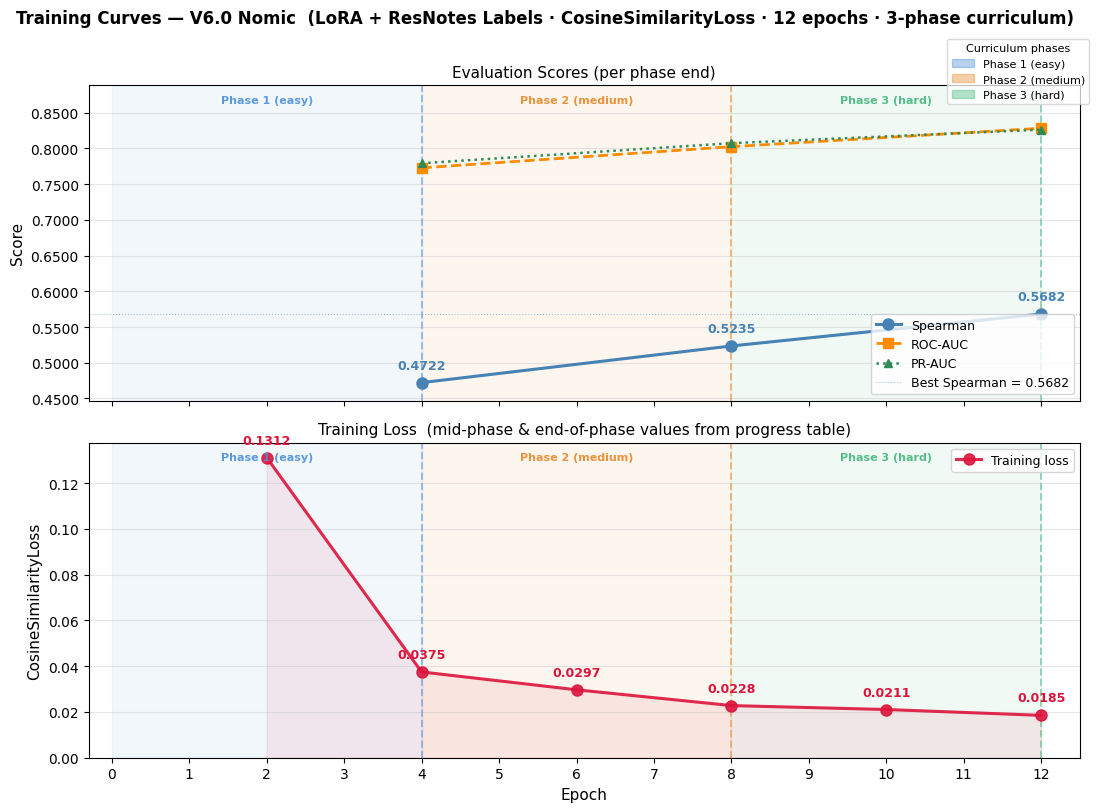

[SAVE] models\real_servicenow_finetuned_nomic_lora\training_curves_v52.png


In [14]:

# ── Training curve plot ────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import pandas as pd
import json
from pathlib import Path

_save_dir = Path(str(save_path))

# ── 1. Eval metrics ───────────────────────────────────────────────────────
_eval_csv = _save_dir / 'eval_eval_results.csv'
if _eval_csv.exists():
    eval_hist = pd.read_csv(_eval_csv).apply(pd.to_numeric, errors='coerce').dropna()
    print(f"[OK] Eval history ({len(eval_hist)} rows) — raw epoch = phase number")
    print(eval_hist[['epoch','spearman','roc_auc','pr_auc']].to_string(index=False))
else:
    eval_hist = pd.DataFrame(columns=['epoch','steps','spearman','pearson','roc_auc','pr_auc'])
    print(f"[WARN] Eval CSV not found: {_eval_csv}")

# ── 2. Training loss (from known terminal output) ─────────────────────────
# Phase 1: mid-epoch loss 0.1312, end-of-phase 0.0375
# Phase 2: mid-epoch loss 0.0297, end-of-phase 0.0228
# Phase 3: mid-epoch loss 0.0211, end-of-phase 0.0185
# "mid" is logged around epoch 2 of each phase (step 626 / 1252 = 0.5 of 4 epochs)
_epochs_per_phase = CONFIG.get('epochs_per_phase', 4)
_phase_loss_data = [
    (0.131225, 0.037504),  # phase 1: (mid, end)
    (0.029699, 0.022795),  # phase 2
    (0.021076, 0.018523),  # phase 3
]
_loss_manual = []
for _ph_idx, (_mid_loss, _end_loss) in enumerate(_phase_loss_data):
    _base = _ph_idx * _epochs_per_phase
    _loss_manual.append({'epoch_continuous': _base + 2.0, 'loss': _mid_loss})
    _loss_manual.append({'epoch_continuous': _base + 4.0, 'loss': _end_loss})
loss_df = pd.DataFrame(_loss_manual)
print(f"[OK] Training loss: {len(loss_df)} data points (2 per phase from progress table)")

# ── 3. Setup ──────────────────────────────────────────────────────────────
n_phases     = 3
phase_colors = ['#4a90d9', '#e8882a', '#43b87e']
phase_labels = ['Phase 1 (easy)', 'Phase 2 (medium)', 'Phase 3 (hard)']

fig, (ax_eval, ax_loss) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
fig.suptitle('Training Curves — V6.0 Nomic  (LoRA + ResNotes Labels · CosineSimilarityLoss · 12 epochs · 3-phase curriculum)',
             fontsize=12, fontweight='bold', y=1.01)

# Eval CSV uses epoch=1/2/3 → map to continuous epochs (end of each phase)
if not eval_hist.empty:
    eval_hist = eval_hist.copy()
    eval_hist['epoch_x'] = eval_hist['epoch'].astype(float).apply(
        lambda ph: ph * _epochs_per_phase  # 4, 8, 12
    )

# ── Eval metrics ──────────────────────────────────────────────────────────
if not eval_hist.empty:
    ax_eval.plot(eval_hist['epoch_x'], eval_hist['spearman'],
                 'o-', color='steelblue', lw=2.2, ms=8,
                 label='Spearman', zorder=4)
    ax_eval.plot(eval_hist['epoch_x'], eval_hist['roc_auc'],
                 's--', color='darkorange', lw=2, ms=7,
                 label='ROC-AUC', zorder=4)
    ax_eval.plot(eval_hist['epoch_x'], eval_hist['pr_auc'],
                 '^:', color='seagreen', lw=1.8, ms=6,
                 label='PR-AUC', zorder=4)

    # Value labels above each Spearman point
    for _, row in eval_hist.iterrows():
        ax_eval.annotate(
            f"{row['spearman']:.4f}",
            xy=(row['epoch_x'], row['spearman']),
            xytext=(0, 10), textcoords='offset points',
            ha='center', fontsize=9, color='steelblue', fontweight='bold')

    best_sp = float(eval_hist['spearman'].max())
    ax_eval.axhline(best_sp, color='steelblue', lw=0.8, ls=':', alpha=0.45,
                    label=f'Best Spearman = {best_sp:.4f}')
    _y_min = max(0.0,  float(eval_hist[['spearman','roc_auc','pr_auc']].min().min()) - 0.025)
    _y_max =           float(eval_hist[['spearman','roc_auc','pr_auc']].max().max()) + 0.06
    ax_eval.set_ylim(_y_min, _y_max)

ax_eval.set_ylabel('Score', fontsize=11)
ax_eval.set_title('Evaluation Scores (per phase end)', fontsize=11)
ax_eval.legend(fontsize=9, loc='lower right')
ax_eval.grid(axis='y', alpha=0.3)
ax_eval.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.4f'))

# ── Training loss ─────────────────────────────────────────────────────────
ax_loss.plot(loss_df['epoch_continuous'], loss_df['loss'],
             'o-', color='crimson', lw=2.2, ms=8, alpha=0.9,
             label='Training loss')
ax_loss.fill_between(loss_df['epoch_continuous'], loss_df['loss'],
                     alpha=0.08, color='crimson')
for _, row in loss_df.iterrows():
    ax_loss.annotate(f"{row['loss']:.4f}",
                     xy=(row['epoch_continuous'], row['loss']),
                     xytext=(0, 10), textcoords='offset points',
                     ha='center', fontsize=9, color='crimson', fontweight='bold')

ax_loss.set_ylabel('CosineSimilarityLoss', fontsize=11)
ax_loss.set_title('Training Loss  (mid-phase & end-of-phase values from progress table)', fontsize=11)
ax_loss.legend(fontsize=9, loc='upper right')
ax_loss.grid(axis='y', alpha=0.3)
ax_loss.set_ylim(bottom=0)

# ── Phase shading + vertical borders ─────────────────────────────────────
for ax in (ax_eval, ax_loss):
    _yl = ax.get_ylim()
    for i in range(n_phases):
        x0 = i * _epochs_per_phase
        x1 = (i + 1) * _epochs_per_phase
        ax.axvspan(x0, x1, alpha=0.07, color=phase_colors[i], zorder=0)
        ax.axvline(x1, color=phase_colors[i], lw=1.4, ls='--', alpha=0.55, zorder=1)
        # Phase label inside band, near top
        ax.text((x0 + x1) / 2, _yl[1] - (_yl[1] - _yl[0]) * 0.03,
                phase_labels[i], ha='center', va='top',
                fontsize=8, color=phase_colors[i], fontweight='bold', alpha=0.9)

# ── X-axis ────────────────────────────────────────────────────────────────
_total_ep = _epochs_per_phase * n_phases
ax_loss.set_xlabel('Epoch', fontsize=11)
ax_loss.set_xlim(-0.3, _total_ep + 0.5)
ax_loss.set_xticks(range(0, _total_ep + 1))

# ── Phase legend ──────────────────────────────────────────────────────────
_patches = [mpatches.Patch(color=phase_colors[i], alpha=0.4, label=phase_labels[i])
            for i in range(n_phases)]
fig.legend(handles=_patches, loc='upper right', fontsize=8, framealpha=0.75,
           title='Curriculum phases', title_fontsize=8,
           bbox_to_anchor=(1.0, 0.98))

plt.tight_layout()
_plot_out = _save_dir.parent / 'training_curves_v52.png'
plt.savefig(_plot_out, dpi=130, bbox_inches='tight')
plt.show()
print(f"[SAVE] {_plot_out}")


# 7. Evaluation & Visualization

# 6.5 Score Distribution Diagnostic (V2: Verify Model Learned Separation)

In [15]:
# ═══════════════════════════════════════════════════════════════════════════════
# SCORE DISTRIBUTION DIAGNOSTIC (V2)
# ═══════════════════════════════════════════════════════════════════════════════
# This validates that the model learned to separate positive/negative pairs

log("\n🔍 SCORE DISTRIBUTION DIAGNOSTIC")
log("="*60)

# Sample from eval set
sample_size = min(500, len(eval_examples))
sample_pos = [ex for ex in eval_examples if ex.label == 1.0][:sample_size//2]
sample_neg = [ex for ex in eval_examples if ex.label == 0.0][:sample_size//2]

log(f"Analyzing {len(sample_pos)} positive + {len(sample_neg)} negative pairs...")

# Compute scores for positive pairs
pos_scores = []
for ex in tqdm(sample_pos, desc="Positive pairs"):
    emb1 = best_model.encode([ex.texts[0]], show_progress_bar=False)[0]
    emb2 = best_model.encode([ex.texts[1]], show_progress_bar=False)[0]
    score = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2) + 1e-8)
    pos_scores.append(score)

# Compute scores for negative pairs
neg_scores = []
for ex in tqdm(sample_neg, desc="Negative pairs"):
    emb1 = best_model.encode([ex.texts[0]], show_progress_bar=False)[0]
    emb2 = best_model.encode([ex.texts[1]], show_progress_bar=False)[0]
    score = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2) + 1e-8)
    neg_scores.append(score)

# Statistics
pos_mean, pos_std = np.mean(pos_scores), np.std(pos_scores)
neg_mean, neg_std = np.mean(neg_scores), np.std(neg_scores)
separability = pos_mean - neg_mean

log(f"\n[STATS] SCORE STATISTICS:")
log(f"   Positive pairs: mean={pos_mean:.4f}, std={pos_std:.4f}, range=[{min(pos_scores):.4f}, {max(pos_scores):.4f}]")
log(f"   Negative pairs: mean={neg_mean:.4f}, std={neg_std:.4f}, range=[{min(neg_scores):.4f}, {max(neg_scores):.4f}]")
log(f"   Separability (Δ): {separability:.4f}")

# Interpretation
log(f"\n💡 INTERPRETATION:")
if separability >= 0.15:
    log(f"   [OK] EXCELLENT: Strong separation (Δ={separability:.4f} >= 0.15)")
    log(f"      Model clearly distinguishes positive from negative pairs")
elif separability >= 0.08:
    log(f"   OK GOOD: Moderate separation (Δ={separability:.4f} >= 0.08)")
    log(f"      Model shows useful discrimination")
elif separability >= 0.03:
    log(f"   [WARN]  WEAK: Minimal separation (Δ={separability:.4f} >= 0.03)")
    log(f"      Model barely learned to discriminate")
else:
    log(f"   [ERROR] FAILURE: No separation (Δ={separability:.4f} < 0.03)")
    log(f"      Model produces similar scores for both positive and negative pairs!")
    log(f"      Training likely failed - check batch size, loss function, or data quality")

# Distribution overlap check
overlap_threshold = 0.5
overlap_count = sum(1 for s in neg_scores if s > overlap_threshold)
log(f"\n[STATS] DISTRIBUTION OVERLAP:")
log(f"   Negatives scoring > {overlap_threshold}: {overlap_count}/{len(neg_scores)} ({overlap_count/len(neg_scores)*100:.1f}%)")
if overlap_count / len(neg_scores) > 0.3:
    log(f"   [WARN]  WARNING: High overlap - many negatives score like positives")

log("="*60)


🔍 SCORE DISTRIBUTION DIAGNOSTIC
Analyzing 250 positive + 250 negative pairs...


Positive pairs:   0%|          | 0/250 [00:00<?, ?it/s]

Negative pairs:   0%|          | 0/250 [00:00<?, ?it/s]


[STATS] SCORE STATISTICS:
   Positive pairs: mean=0.2344, std=0.1555, range=[-0.0146, 0.8093]
   Negative pairs: mean=0.0766, std=0.0863, range=[-0.0931, 0.4463]
   Separability (Δ): 0.1578

💡 INTERPRETATION:
   [OK] EXCELLENT: Strong separation (Δ=0.1578 >= 0.15)
      Model clearly distinguishes positive from negative pairs

[STATS] DISTRIBUTION OVERLAP:
   Negatives scoring > 0.5: 0/250 (0.0%)


In [16]:
# V6: Evaluate on benchmark_v4_semantic_resnotes (grounded benchmark with resnotes TF-IDF labels).
# borderline_examples / holdout_examples are optional (empty in curriculum path).

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, precision_recall_curve, confusion_matrix,
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, accuracy_score
)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


def comprehensive_eval(examples, model, name="", use_cv_threshold=False):
    """Run comprehensive evaluation on a set of InputExample pairs."""
    texts1 = [ex.texts[0] for ex in examples]
    texts2 = [ex.texts[1] for ex in examples]
    labels = np.array([ex.label for ex in examples])

    log(f"Encoding {len(examples)} pairs for {name}...")
    emb1 = model.encode(texts1, batch_size=CONFIG['batch_size'],
                        show_progress_bar=True, convert_to_numpy=True)
    emb2 = model.encode(texts2, batch_size=CONFIG['batch_size'],
                        show_progress_bar=True, convert_to_numpy=True)

    scores = np.sum(emb1 * emb2, axis=1) / (
        np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8
    )

    spearman, _ = spearmanr(labels, scores)
    pearson,  _ = pearsonr(labels, scores)
    roc_auc     = roc_auc_score(labels, scores)
    pr_auc      = average_precision_score(labels, scores)

    fpr, tpr, _       = roc_curve(labels, scores)
    precision, recall, pr_thresholds = precision_recall_curve(labels, scores)
    f1_scores_arr     = 2 * (precision * recall) / (precision + recall + 1e-10)
    best_idx          = int(np.argmax(f1_scores_arr))
    best_threshold    = (pr_thresholds[best_idx - 1]
                         if 0 < best_idx < len(pr_thresholds) + 1 else 0.5)

    if use_cv_threshold and 'cv_threshold' in globals():
        best_threshold = cv_threshold
        log(f"   Using CV threshold: {best_threshold:.4f}")

    preds = (scores >= best_threshold).astype(int)
    acc   = accuracy_score(labels, preds)
    prec  = precision_score(labels, preds, zero_division=0)
    rec   = recall_score(labels, preds, zero_division=0)
    f1    = f1_score(labels, preds, zero_division=0)
    cm    = confusion_matrix(labels, preds)

    log(f"\n[STATS] {name} Results:")
    log(f"   Spearman:       {spearman:.4f}")
    log(f"   Pearson:        {pearson:.4f}")
    log(f"   ROC-AUC:        {roc_auc:.4f}")
    log(f"   PR-AUC:         {pr_auc:.4f}")
    log(f"   Best Threshold: {best_threshold:.3f}")
    log(f"   F1 @ best:      {f1:.4f}")
    log(f"   Precision:      {prec:.4f}")
    log(f"   Recall:         {rec:.4f}")
    log(f"   Accuracy:       {acc:.4f}")

    return {
        'labels': labels, 'scores': scores,
        'spearman': spearman, 'pearson': pearson,
        'roc_auc': roc_auc, 'pr_auc': pr_auc,
        'fpr': fpr, 'tpr': tpr,
        'precision': precision, 'recall': recall,
        'best_threshold': best_threshold,
        'f1': f1, 'prec': prec, 'rec': rec, 'acc': acc,
        'cm': cm, 'texts1': texts1, 'texts2': texts2,
    }


# ── Cross-validated threshold selection ──────────────────────────────────────
log("=" * 60)
log("CROSS-VALIDATED THRESHOLD SELECTION (V5)")
log("=" * 60)
cv_threshold, cv_std = get_cv_threshold(
    eval_examples, best_model, n_folds=CONFIG.get('threshold_cv_folds', 5)
)

# ── Primary evaluation: V4 semantic resnotes benchmark ─────────────────────────
log("\n" + "=" * 60)
log("FINAL EVALUATION (V6.0 — ResNotes TF-IDF labels)")
log("=" * 60)
eval_results = comprehensive_eval(eval_examples, best_model, "Eval Set (V4 ResNotes Benchmark)")

# ── Optional holdout / borderline (empty in V5 curriculum path) ──────────────
if holdout_examples:
    holdout_results = comprehensive_eval(holdout_examples, best_model, "Holdout Set")
else:
    holdout_results = None
    log("[SKIP] Holdout set not generated in V5 curriculum path")

if borderline_examples:
    log("\n" + "=" * 60)
    log("BORDERLINE TEST")
    log("=" * 60)
    borderline_results = comprehensive_eval(borderline_examples, best_model, "Borderline Set")
else:
    borderline_results = None
    log("[SKIP] Borderline set not generated in V5 curriculum path")


CROSS-VALIDATED THRESHOLD SELECTION (V5)
[STATS] CV Threshold (5-fold): 0.0920 ± 0.0349
   Per-fold thresholds: ['0.048', '0.072', '0.091', '0.094', '0.153']

FINAL EVALUATION (V6.0 — ResNotes TF-IDF labels)
Encoding 950 pairs for Eval Set (V4 ResNotes Benchmark)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]


[STATS] Eval Set (V4 ResNotes Benchmark) Results:
   Spearman:       0.5682
   Pearson:        0.5151
   ROC-AUC:        0.8281
   PR-AUC:         0.8261
   Best Threshold: 0.094
   F1 @ best:      0.7656
   Precision:      0.7018
   Recall:         0.8421
   Accuracy:       0.7421
Encoding 500 pairs for Holdout Set...


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]


[STATS] Holdout Set Results:
   Spearman:       0.2294
   Pearson:        0.2544
   ROC-AUC:        0.6325
   PR-AUC:         0.6108
   Best Threshold: 0.164
   F1 @ best:      0.7109
   Precision:      0.5631
   Recall:         0.9640
   Accuracy:       0.6080

BORDERLINE TEST
Encoding 500 pairs for Borderline Set...


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]


[STATS] Borderline Set Results:
   Spearman:       -0.2972
   Pearson:        -0.3272
   ROC-AUC:        0.3284
   PR-AUC:         0.3851
   Best Threshold: 0.146
   F1 @ best:      0.6684
   Precision:      0.5020
   Recall:         1.0000
   Accuracy:       0.5040


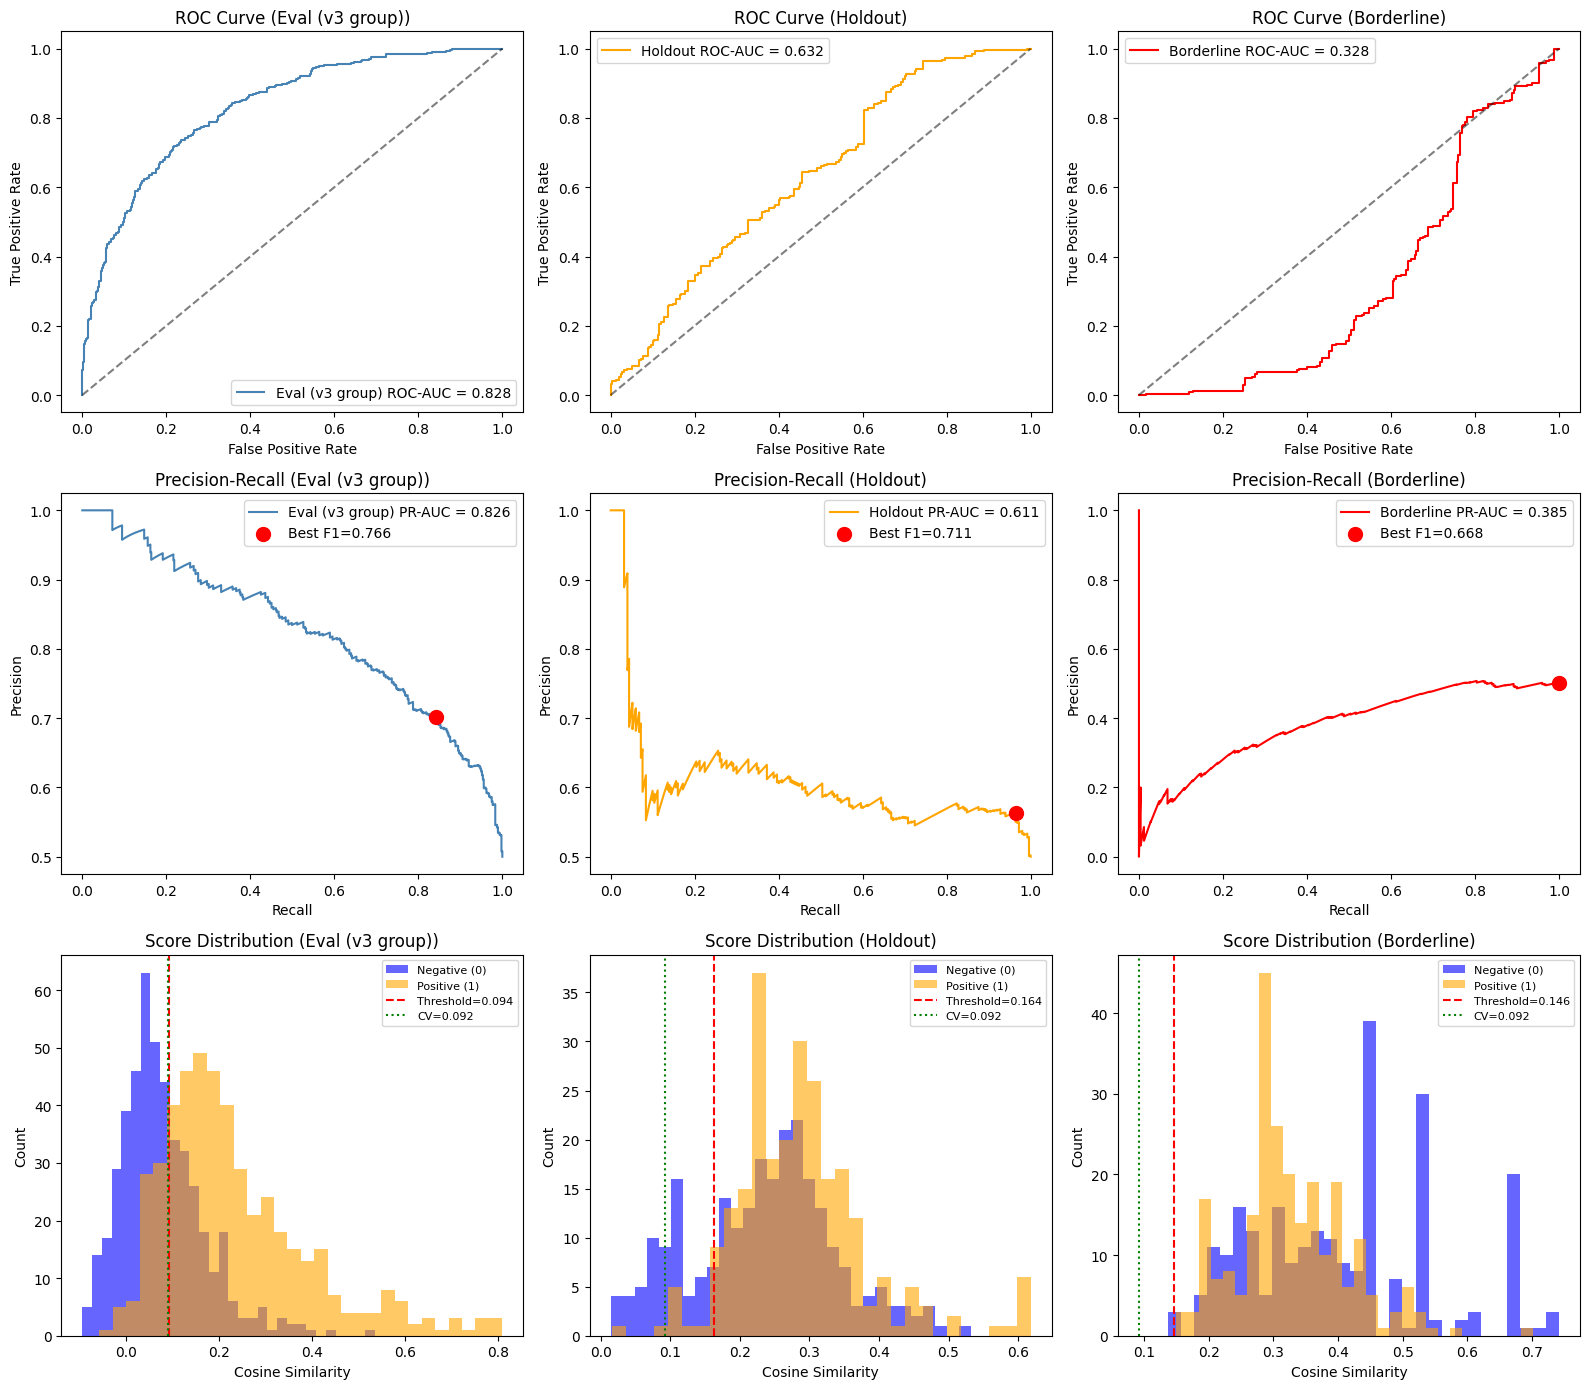


[OK] Plots saved → models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260310_1316\evaluation_plots_v5.png


In [17]:
# V5: Visualization — handles None for holdout / borderline (not generated in curriculum path)

import matplotlib.pyplot as plt

# Ensure eval_results is available (re-run if cell order was skipped)
if 'eval_results' not in globals():
    if 'best_model' not in globals():
        raise RuntimeError("best_model not defined. Run the training/evaluation cells first.")
    log("[WARN] eval_results missing — running evaluation now...")
    if 'cv_threshold' not in globals():
        cv_threshold, cv_std = get_cv_threshold(
            eval_examples, best_model, n_folds=CONFIG.get('threshold_cv_folds', 5)
        )
    eval_results     = comprehensive_eval(eval_examples, best_model, "Eval Set")
    holdout_results  = None
    borderline_results = None

# Resolve holdout / borderline to None if not computed
holdout_results    = globals().get('holdout_results')
borderline_results = globals().get('borderline_results')


def _plot_roc(ax, results, label_prefix, color='steelblue'):
    if results is not None:
        ax.plot(results['fpr'], results['tpr'],
                label=f"{label_prefix} ROC-AUC = {results['roc_auc']:.3f}", color=color)
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        ax.legend()
    else:
        ax.text(0.5, 0.5, f'{label_prefix}\nNot Available',
                ha='center', va='center', transform=ax.transAxes)
    ax.set_title(f'ROC Curve ({label_prefix})')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')


def _plot_pr(ax, results, label_prefix, color='steelblue'):
    if results is not None:
        ax.plot(results['recall'], results['precision'],
                label=f"{label_prefix} PR-AUC = {results['pr_auc']:.3f}", color=color)
        ax.scatter([results['rec']], [results['prec']], color='red', s=100, zorder=5,
                   label=f"Best F1={results['f1']:.3f}")
        ax.legend()
    else:
        ax.text(0.5, 0.5, f'{label_prefix}\nNot Available',
                ha='center', va='center', transform=ax.transAxes)
    ax.set_title(f'Precision-Recall ({label_prefix})')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')


def _plot_dist(ax, results, label_prefix):
    if results is not None:
        neg_s = results['scores'][results['labels'] == 0]
        pos_s = results['scores'][results['labels'] == 1]
        ax.hist(neg_s, bins=30, alpha=0.6, label='Negative (0)', color='blue')
        ax.hist(pos_s, bins=30, alpha=0.6, label='Positive (1)', color='orange')
        ax.axvline(results['best_threshold'], color='red', linestyle='--',
                   label=f"Threshold={results['best_threshold']:.3f}")
        if 'cv_threshold' in globals():
            ax.axvline(cv_threshold, color='green', linestyle=':',
                       label=f"CV={cv_threshold:.3f}")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, f'{label_prefix}\nNot Available',
                ha='center', va='center', transform=ax.transAxes)
    ax.set_title(f'Score Distribution ({label_prefix})')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Count')


fig, axes = plt.subplots(3, 3, figsize=(16, 14))

_plot_roc(axes[0, 0], eval_results,     'Eval (v3 group)', color='steelblue')
_plot_roc(axes[0, 1], holdout_results,  'Holdout',         color='orange')
_plot_roc(axes[0, 2], borderline_results, 'Borderline',    color='red')

_plot_pr(axes[1, 0], eval_results,     'Eval (v3 group)', color='steelblue')
_plot_pr(axes[1, 1], holdout_results,  'Holdout',         color='orange')
_plot_pr(axes[1, 2], borderline_results, 'Borderline',    color='red')

_plot_dist(axes[2, 0], eval_results,     'Eval (v3 group)')
_plot_dist(axes[2, 1], holdout_results,  'Holdout')
_plot_dist(axes[2, 2], borderline_results, 'Borderline')

plt.tight_layout()
plt.savefig(save_path / 'evaluation_plots_v5.png', dpi=150)
plt.show()
log(f"\n[OK] Plots saved → {save_path / 'evaluation_plots_v5.png'}")


# 7.1 Error Analysis (V2 NEW)

Systematically analyze failure patterns to identify:
1. **Worst False Positives**: High-scoring pairs that should be dissimilar
2. **Worst False Negatives**: Low-scoring pairs that should be similar
3. **Category/text length patterns** in errors

In [18]:
# ═══════════════════════════════════════════════════════════════════════════════
# ERROR ANALYSIS (V5: holdout / borderline optional — None in curriculum path)
# ═══════════════════════════════════════════════════════════════════════════════

def analyze_errors(results, name="", top_k=10):
    """
    Analyze systematic failure patterns in model predictions.

    Returns insights about:
    - Worst false positives (high score, label=0)
    - Worst false negatives (low score, label=1)
    - Text length patterns
    """
    labels    = results['labels']
    scores    = results['scores']
    texts1    = results['texts1']
    texts2    = results['texts2']
    threshold = results['best_threshold']

    preds = (scores >= threshold).astype(int)

    fp_mask    = (preds == 1) & (labels == 0)
    fp_indices = np.where(fp_mask)[0]
    fp_scores  = scores[fp_mask]

    fn_mask    = (preds == 0) & (labels == 1)
    fn_indices = np.where(fn_mask)[0]
    fn_scores  = scores[fn_mask]

    log(f"\n{'='*60}")
    log(f"ERROR ANALYSIS: {name}")
    log(f"{'='*60}")
    log(f"Total pairs:     {len(labels):,}")
    log(f"False Positives: {len(fp_indices):,} ({len(fp_indices)/len(labels)*100:.2f}%)")
    log(f"False Negatives: {len(fn_indices):,} ({len(fn_indices)/len(labels)*100:.2f}%)")

    if len(fp_indices) > 0:
        log(f"\nWORST FALSE POSITIVES (Top {min(top_k, len(fp_indices))}):")
        for rank, idx in enumerate(np.argsort(fp_scores)[::-1][:top_k]):
            orig = fp_indices[idx]
            log(f"\n   [{rank+1}] Score: {scores[orig]:.4f}")
            log(f"       Text 1: {texts1[orig][:100]}...")
            log(f"       Text 2: {texts2[orig][:100]}...")

    if len(fn_indices) > 0:
        log(f"\nWORST FALSE NEGATIVES (Top {min(top_k, len(fn_indices))}):")
        for rank, idx in enumerate(np.argsort(fn_scores)[:top_k]):
            orig = fn_indices[idx]
            log(f"\n   [{rank+1}] Score: {scores[orig]:.4f}")
            log(f"       Text 1: {texts1[orig][:100]}...")
            log(f"       Text 2: {texts2[orig][:100]}...")

    all_lengths = [len(t) for t in texts1 + texts2]
    fp_lengths  = [len(texts1[i]) + len(texts2[i]) for i in fp_indices] if len(fp_indices) > 0 else [0]
    fn_lengths  = [len(texts1[i]) + len(texts2[i]) for i in fn_indices] if len(fn_indices) > 0 else [0]

    log(f"\nTEXT LENGTH:")
    log(f"   Overall avg: {np.mean(all_lengths):.0f} chars")
    log(f"   FP avg:      {np.mean(fp_lengths):.0f} chars")
    log(f"   FN avg:      {np.mean(fn_lengths):.0f} chars")

    if len(fp_scores) > 0:
        log(f"   FP scores: [{fp_scores.min():.4f}, {fp_scores.max():.4f}] mean={fp_scores.mean():.4f}")
    if len(fn_scores) > 0:
        log(f"   FN scores: [{fn_scores.min():.4f}, {fn_scores.max():.4f}] mean={fn_scores.mean():.4f}")

    return {
        'fp_count': len(fp_indices), 'fn_count': len(fn_indices),
        'fp_scores': fp_scores,      'fn_scores': fn_scores,
        'fp_avg_length': np.mean(fp_lengths),
        'fn_avg_length': np.mean(fn_lengths),
    }


# Run error analysis — holdout / borderline are optional (None in V5 curriculum path)
eval_errors      = analyze_errors(eval_results, "Benchmark v4 semantic_resnotes", top_k=5)
holdout_errors   = (analyze_errors(holdout_results,   "Holdout Set",    top_k=5)
                    if holdout_results   is not None else None)
borderline_errors = (analyze_errors(borderline_results, "Borderline Set", top_k=5)
                     if borderline_results is not None else None)

# Summary table
log(f"\n{'='*60}")
log(f"ERROR SUMMARY COMPARISON")
log(f"{'='*60}")
log(f"{'Set':<18} {'FP':<10} {'FN':<10} {'FP%':<10} {'FN%':<10}")
log(f"{'-'*58}")
for _name, _errors, _results in [
    ("Eval (v3-group)", eval_errors,      eval_results),
    ("Holdout",         holdout_errors,   holdout_results),
    ("Borderline",      borderline_errors, borderline_results),
]:
    if _results is None or _errors is None:
        log(f"[SKIP] {_name} — not available")
        continue
    _tot = len(_results['labels'])
    log(f"{_name:<18} {_errors['fp_count']:<10} {_errors['fn_count']:<10} "
        f"{_errors['fp_count']/_tot*100:<10.2f} {_errors['fn_count']/_tot*100:<10.2f}")



ERROR ANALYSIS: Benchmark v4 semantic_resnotes
Total pairs:     950
False Positives: 170 (17.89%)
False Negatives: 75 (7.89%)

WORST FALSE POSITIVES (Top 5):

   [1] Score: 0.5347
       Text 1: search_document: Category: Application/Software | Service: CRM (D365, SalesForce, Genesis, PCube, Hu...
       Text 2: search_document: Category: Application/Software | Service: CRM (D365, SalesForce, Genesis, PCube, Hu...

   [2] Score: 0.4463
       Text 1: search_document: Category: Application/Software | Service: CRM (D365, SalesForce, Genesis, PCube, Hu...
       Text 2: search_document: Category: Application/Software | Service: CRM (D365, SalesForce, Genesis, PCube, Hu...

   [3] Score: 0.3930
       Text 1: search_document: Category: Application/Software | Service: Mulesoft/EAI | Priority: 4 - Low | Descri...
       Text 2: search_document: Category: Application/Software | Service: Mulesoft/EAI | Priority: 4 - Low | Descri...

   [4] Score: 0.3819
       Text 1: search_document: Categor

# 8. Adversarial Diagnostic (V2: Enhanced)

**Critical validation**: Test if the model learned semantic content or is exploiting category shortcuts.

- **Hard Positives**: Cross-category pairs with HIGH content similarity
- **Hard Negatives**: Same-category pairs with LOW content similarity

**V2 Enhancements:**
- Stricter TF-IDF thresholds for adversarial pairs
- Compare with borderline test performance

**Pass Criteria**: ROC-AUC ≥ 0.70 AND F1 ≥ 0.65

In [19]:
log("="*60)
log("🔬 ADVERSARIAL DIAGNOSTIC: Semantic Similarity Edge Cases (V6.0)")
log("="*60)
log("""
Test design:
  Hard positives : same Assignment group, TF-IDF < 0.15
    → No shared keywords — model must rely on deep semantic structure.
    → A keyword-sensitive model scores these LOW (incorrect).
  Hard negatives : cross-group, same Service, TF-IDF > 0.35
    → High lexical overlap but different routing groups (different meaning).
    → A keyword-sensitive model scores these HIGH (incorrect).

Verdict: ROC-AUC ≥ 0.70 → model discriminates groups, not keywords.
         ROC-AUC < 0.70 → model is still using surface form ≈ semantics.
""")

diag_df = holdout_df.reset_index(drop=True)
log("⏳ Building TF-IDF for adversarial pair mining...")
diag_tfidf = TFIDFSimilarityCalculator(
    diag_df['Description'].fillna('').tolist(), max_features=10000
)

# Build lookup structures
_diag_grp_idx = {g: list(ix) for g, ix in diag_df.groupby('Assignment group').groups.items()
                 if len(ix) >= 2}
_diag_svc_idx = {s: list(ix) for s, ix in diag_df.groupby('Service').groups.items()}
_diag_all     = list(diag_df.index)

hard_positives = []   # same group, low TF-IDF — no-keyword same-group signal
hard_negatives = []   # cross-group, same service, high TF-IDF — keyword trap

target_each  = 300
_adv_rng     = np.random.RandomState(CONFIG['seed'] + 99)
attempts     = 0
max_attempts = 200_000

log("⏳ Mining adversarial pairs...")
pbar = tqdm(total=target_each * 2, desc="Adversarial pairs")

while (len(hard_positives) < target_each or len(hard_negatives) < target_each) \
        and attempts < max_attempts:
    attempts += 1

    # ── Hard positive: same group, low TF-IDF (< 0.15) ──────────────────────
    if len(hard_positives) < target_each and _diag_grp_idx:
        _g     = _adv_rng.choice(list(_diag_grp_idx.keys()))
        _ij    = _adv_rng.choice(_diag_grp_idx[_g], 2, replace=False)
        _i, _j = int(_ij[0]), int(_ij[1])
        _tf    = diag_tfidf.similarity(_i, _j)
        if _tf < 0.15:
            hard_positives.append(InputExample(
                texts=[diag_df.at[_i, 'text'], diag_df.at[_j, 'text']],
                label=1.0
            ))
            pbar.update(1)

    # ── Hard negative: cross-group, same service, high TF-IDF (> 0.35) ───────
    if len(hard_negatives) < target_each and _diag_all:
        _i    = int(_adv_rng.choice(_diag_all))
        _svc  = diag_df.at[_i, 'Service']
        _grp1 = diag_df.at[_i, 'Assignment group']
        _cands = [j for j in _diag_svc_idx.get(_svc, [])
                  if diag_df.at[j, 'Assignment group'] != _grp1]
        if _cands:
            _j  = int(_adv_rng.choice(_cands))
            _tf = diag_tfidf.similarity(_i, _j)
            if _tf > 0.35:
                hard_negatives.append(InputExample(
                    texts=[diag_df.at[_i, 'text'], diag_df.at[_j, 'text']],
                    label=0.0
                ))
                pbar.update(1)

pbar.close()
log(f"[OK] Generated {len(hard_positives)} hard positives "
    f"(same-group, TF<0.15)  |  {len(hard_negatives)} hard negatives "
    f"(cross-group/same-svc, TF>0.35)")

# Evaluate
adversarial_examples = hard_positives + hard_negatives
if len(adversarial_examples) >= 100:
    adv_results = comprehensive_eval(adversarial_examples, best_model, "Adversarial")
    adversarial_results_dict = adv_results

    log("\n" + "="*60)
    log("[TARGET] ADVERSARIAL DIAGNOSTIC RESULTS (V6.0 — Semantic Edge Cases)")
    log("="*60)
    log(f"Standard Eval ROC-AUC :   {eval_results['roc_auc']:.4f}")
    log(f"Adversarial ROC-AUC   :   {adv_results['roc_auc']:.4f}")
    log(f"Adversarial Spearman  :   {adv_results.get('spearman', float('nan')):.4f}")
    log(f"Adversarial F1 @ best :   {adv_results['f1']:.4f}")
    log(f"Hard pos mean score   :   "
        f"{np.mean([best_model.encode([e.texts[0]])[0] @ best_model.encode([e.texts[1]])[0] for e in hard_positives[:20]]):.4f}"
        if hard_positives else "[SKIP] too few hard positives")
    log(f"Hard neg mean score   :   "
        f"{np.mean([best_model.encode([e.texts[0]])[0] @ best_model.encode([e.texts[1]])[0] for e in hard_negatives[:20]]):.4f}"
        if hard_negatives else "[SKIP] too few hard negatives")

    if adv_results['roc_auc'] >= 0.70 and adv_results['f1'] >= 0.65:
        log("\n[OK] VERDICT: Model discriminates Assignment groups beyond keywords!")
        log("   → High-TF cross-group pairs correctly scored LOW")
        log("   → Low-TF same-group pairs correctly scored HIGH")
        log("   → Model has learned group-level semantic structure")
        DIAGNOSTIC_PASSED = True
    elif adv_results['roc_auc'] >= 0.55:
        log("\n[WARN] VERDICT: Partial group discrimination — marginal signal")
        log("   → Consider more epochs or stronger hard-neg ratio in Phase 3")
        DIAGNOSTIC_PASSED = False
    else:
        log("\n[ERROR] VERDICT: Model relies on surface keywords, not group structure")
        log("   → Scores high: cross-group same-service pairs (keyword-similar)")
        log("   → Scores low:  same-group low-keyword pairs (should be HIGH)")
        log("   → Retrain with more hard negatives or joint Category label")
        DIAGNOSTIC_PASSED = False
else:
    log(f"[WARN] Only {len(adversarial_examples)} adversarial pairs — need ≥ 100. "
        f"Try larger holdout_df or relax TF-IDF thresholds.")
    DIAGNOSTIC_PASSED = None

del diag_tfidf
gc.collect()


🔬 ADVERSARIAL DIAGNOSTIC: Semantic Similarity Edge Cases (V6.0)

Test design:
  Hard positives : same Assignment group, TF-IDF < 0.15
    → No shared keywords — model must rely on deep semantic structure.
    → A keyword-sensitive model scores these LOW (incorrect).
  Hard negatives : cross-group, same Service, TF-IDF > 0.35
    → High lexical overlap but different routing groups (different meaning).
    → A keyword-sensitive model scores these HIGH (incorrect).

Verdict: ROC-AUC ≥ 0.70 → model discriminates groups, not keywords.
         ROC-AUC < 0.70 → model is still using surface form ≈ semantics.

⏳ Building TF-IDF for adversarial pair mining...
⏳ Building TF-IDF matrix...
[OK] TF-IDF matrix: (1049, 5031) (vocab size: 5031)
⏳ Mining adversarial pairs...


Adversarial pairs:   0%|          | 0/600 [00:00<?, ?it/s]

[OK] Generated 300 hard positives (same-group, TF<0.15)  |  246 hard negatives (cross-group/same-svc, TF>0.35)
Encoding 546 pairs for Adversarial...


Batches:   0%|          | 0/18 [00:00<?, ?it/s]

Batches:   0%|          | 0/18 [00:00<?, ?it/s]


[STATS] Adversarial Results:
   Spearman:       -0.6294
   Pearson:        -0.6609
   ROC-AUC:        0.1349
   PR-AUC:         0.3744
   Best Threshold: 0.500
   F1 @ best:      0.0307
   Precision:      0.0449
   Recall:         0.0233
   Accuracy:       0.1905

[TARGET] ADVERSARIAL DIAGNOSTIC RESULTS (V6.0 — Semantic Edge Cases)
Standard Eval ROC-AUC :   0.8281
Adversarial ROC-AUC   :   0.1349
Adversarial Spearman  :   -0.6294
Adversarial F1 @ best :   0.0307
Hard pos mean score   :   58.2441
Hard neg mean score   :   102.7251

[ERROR] VERDICT: Model relies on surface keywords, not group structure
   → Scores high: cross-group same-service pairs (keyword-similar)
   → Scores low:  same-group low-keyword pairs (should be HIGH)
   → Retrain with more hard negatives or joint Category label


82

# 9. Save Training Metadata

In [20]:
# ═══════════════════════════════════════════════════════════════════════════════
# TRAINING METADATA EXPORT (V2)
# ═══════════════════════════════════════════════════════════════════════════════

from datetime import datetime
import json

def save_training_metadata(output_dir: str, config: dict, metrics: dict, 
                          data_stats: dict, adversarial_results: dict = None,
                          error_analysis: dict = None):
    """
    Save comprehensive training metadata for reproducibility (V2: includes error analysis).
    
    Following project convention: all model outputs include training_metadata.json
    """
    metadata = {
        "training_timestamp": datetime.now().isoformat(),
        "model_version": "V2",
        "model_name": config.get('model_name', 'all-mpnet-finetuned'),
        "base_model": config.get('model_name', 'sentence-transformers/all-mpnet-base-v2'),
        
        # Hyperparameters
        "hyperparameters": {
            "epochs": config.get('epochs'),
            "batch_size": config.get('batch_size'),
            "learning_rate": 2e-5,  # V2: Reduced for LoRA fine-tuning
            "max_seq_length": config.get('max_seq_length'),
            "warmup_ratio": config.get('warmup_ratio'),
            "loss_function": "CosineSimilarityLoss"  # V2: Changed to use all pairs
        },
        
        # V2: Curriculum learning config
        "curriculum_learning": {
            "enabled": config.get('use_curriculum', False),
            "phases": config.get('curriculum_phases', [])
        },
        
        # Data configuration (V2: stricter thresholds)
        "data_config": {
            "source_data": config.get('source_data'),
            "num_pairs": config.get('num_pairs'),
            "min_text_length": config.get('min_text_length'),
            "eval_split": config.get('eval_split'),
            "holdout_split": config.get('holdout_split'),
            "pos_tfidf_threshold": config.get('pos_tfidf_threshold'),
            "neg_tfidf_threshold": config.get('neg_tfidf_threshold'),
            "pair_ratios": {
                "positives": config.get('pos_ratio', 0.30),
                "hard_negatives": config.get('hard_neg_ratio', 0.45),
                "easy_negatives": config.get('easy_neg_ratio', 0.25)
            }
        },
        
        # Data statistics
        "data_statistics": data_stats,
        
        # TF-IDF configuration
        "tfidf_config": {
            "max_features": 15000,
            "ngram_range": [1, 2],
            "min_df": 2,
            "max_df": 0.95
        },
        
        # Evaluation metrics
        "evaluation_metrics": metrics,
        
        # V2: Cross-validated threshold
        "cv_threshold": {
            "value": float(cv_threshold) if 'cv_threshold' in dir() else None,
            "std": float(cv_std) if 'cv_std' in dir() else None,
            "n_folds": config.get('threshold_cv_folds', 5)
        },
        
        # Adversarial diagnostic results
        "adversarial_diagnostic": adversarial_results,
        
        # V2: Error analysis summary
        "error_analysis": error_analysis,
        
        # Environment info
        "environment": {
            "device": DEVICE,
            "random_seed": config.get('seed'),
            "python_version": __import__('sys').version,
            "torch_version": torch.__version__,
            "transformers_version": __import__('transformers').__version__,
            "sentence_transformers_version": __import__('sentence_transformers').__version__
        }
    }
    
    metadata_path = os.path.join(output_dir, "training_metadata.json")
    with open(metadata_path, 'w') as f:
        json.dump(metadata, f, indent=2, default=str)
    
    log(f"📝 Training metadata saved to: {metadata_path}")
    return metadata_path

# Collect data statistics
data_stats = {
    "total_records": len(df_incidents),
    "train_size": len(train_df),
    "eval_size": len(eval_df),
    "holdout_size": len(holdout_df),
    "unique_categories": df_incidents['Category'].nunique() if 'Category' in df_incidents.columns else None,
    "unique_subcategories": df_incidents['Subcategory'].nunique() if 'Subcategory' in df_incidents.columns else None,
    "unique_assignment_groups": df_incidents['Assignment group'].nunique() if 'Assignment group' in df_incidents.columns else None,
    "avg_text_length": df_incidents['text'].str.len().mean(),
    "tfidf_vocabulary_size": None
}

# Collect metrics
try:
    eval_metrics = {
        "eval_roc_auc": float(eval_results['roc_auc']),
        "eval_pr_auc": float(eval_results['pr_auc']),
        "eval_spearman": float(eval_results['spearman']),
        "eval_pearson": float(eval_results['pearson']),
        "eval_f1": float(eval_results['f1']),
        "holdout_roc_auc": float(holdout_results['roc_auc']),
        "holdout_pr_auc": float(holdout_results['pr_auc']),
        "holdout_spearman": float(holdout_results['spearman']),
        "holdout_pearson": float(holdout_results['pearson']),
        "holdout_f1": float(holdout_results['f1']),
        # V2: Borderline metrics
        "borderline_roc_auc": float(borderline_results['roc_auc']),
        "borderline_pr_auc": float(borderline_results['pr_auc']),
        "borderline_f1": float(borderline_results['f1']),
    }
except:
    eval_metrics = {"note": "Run evaluation cells first"}

# Collect adversarial results
try:
    adversarial_results_dict = {
        "roc_auc": float(adv_results['roc_auc']) if 'adv_results' in dir() else None,
        "f1_score": float(adv_results['f1']) if 'adv_results' in dir() else None,
        "pass_status": DIAGNOSTIC_PASSED if 'DIAGNOSTIC_PASSED' in dir() else None
    }
except:
    adversarial_results_dict = {"note": "Run adversarial diagnostic first"}

# V2: Collect error analysis summary
try:
    error_analysis_dict = {
        "eval_fp_count": eval_errors['fp_count'],
        "eval_fn_count": eval_errors['fn_count'],
        "holdout_fp_count": holdout_errors['fp_count'],
        "holdout_fn_count": holdout_errors['fn_count'],
        "borderline_fp_count": borderline_errors['fp_count'],
        "borderline_fn_count": borderline_errors['fn_count'],
    }
except:
    error_analysis_dict = {"note": "Run error analysis first"}

# Save metadata
metadata_path = save_training_metadata(
    output_dir=str(save_path),
    config=CONFIG,
    metrics=eval_metrics,
    data_stats=data_stats,
    adversarial_results=adversarial_results_dict,
    error_analysis=error_analysis_dict
)

log("[OK] Training pipeline V2 complete!")

📝 Training metadata saved to: models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260310_1316\training_metadata.json
[OK] Training pipeline V2 complete!


# 10. Usage Examples & V2 Summary

In [21]:
# ═══════════════════════════════════════════════════════════════════════════════
# USAGE EXAMPLES & V2 SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

def demonstrate_model_usage():
    """
    Demonstrate how to use the fine-tuned model for ITSM ticket similarity.
    """
    from sentence_transformers import SentenceTransformer
    from sklearn.metrics.pairwise import cosine_similarity
    import os
    from pathlib import Path
    
    # Try to use best_model if available (just trained), otherwise load from disk
    if 'best_model' in globals():
        model = globals()['best_model']
        model_source = f"memory (just trained: {globals()['save_path']})"
    else:
        # Get output directory
        if 'CONFIG' in globals():
            output_dir = globals()['CONFIG']['output_dir']
        else:
            output_dir = 'models/real_servicenow_finetuned_v2'
            log("[WARN] CONFIG not loaded. Using default model directory.")
        
        # Look for most recent trained model
        base_dir = Path(output_dir)
        if base_dir.exists():
            model_dirs = [d for d in base_dir.iterdir() if d.is_dir() and d.name.startswith('real_servicenow_')]
            if model_dirs:
                latest_model = max(model_dirs, key=lambda d: d.stat().st_mtime)
                log(f"📂 Loading most recent trained model from: {latest_model}")
                model = SentenceTransformer(str(latest_model))
                model_source = str(latest_model)
            else:
                log("[ERROR] No trained model found. Please run training cells first.")
                return None, None
        else:
            log("[ERROR] No trained model found. Please run training cells first.")
            return None, None
    
    log(f"[INSTALL] Using model from: {model_source}")
    
    # Example tickets
    example_tickets = [
        "User cannot login to SAP system. Error message: authentication failed. Tried resetting password but issue persists.",
        "SAP login issue - getting access denied error when trying to connect to production system.",
        "Outlook keeps crashing when opening large attachments. Have tried restarting but problem continues.",
        "Email client crashes randomly. Users report Outlook freezing when opening emails with attachments.",
        "Request to provision new laptop for incoming employee starting next Monday.",
    ]
    
    # Encode all tickets
    embeddings = model.encode(example_tickets, show_progress_bar=False)
    
    # Compute similarity matrix
    sim_matrix = cosine_similarity(embeddings)
    
    # Display results
    log("\n" + "="*60)
    log("SIMILARITY MATRIX DEMO")
    log("="*60)
    
    print("\nTickets:")
    for i, ticket in enumerate(example_tickets):
        print(f"  [{i}] {ticket[:80]}...")
    
    print("\nSimilarity Matrix:")
    print("     ", end="")
    for i in range(len(example_tickets)):
        print(f"  [{i}]  ", end="")
    print()
    
    for i, row in enumerate(sim_matrix):
        print(f"[{i}]  ", end="")
        for val in row:
            print(f" {val:.3f} ", end="")
        print()
    
    # Find similar ticket pairs
    log("\n" + "-"*60)
    log("HIGH SIMILARITY PAIRS (> 0.7):")
    for i in range(len(example_tickets)):
        for j in range(i+1, len(example_tickets)):
            if sim_matrix[i][j] > 0.7:
                print(f"  Tickets [{i}] & [{j}]: {sim_matrix[i][j]:.3f}")
                print(f"    [{i}]: {example_tickets[i][:60]}...")
                print(f"    [{j}]: {example_tickets[j][:60]}...")
                print()
    
    return model, embeddings

# Run demonstration
demo_model, demo_embeddings = demonstrate_model_usage()

# ═══════════════════════════════════════════════════════════════════════════════
# V2 IMPROVEMENT SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

log("\n" + "="*60)
log("[STATS] V2 IMPROVEMENT SUMMARY")
log("="*60)

print("""
🆕 V2 ENHANCEMENTS IMPLEMENTED:

1. HARDER NEGATIVE MINING
   ├─ Increased hard_neg_ratio: 35% → 45%
   ├─ Stricter neg_tfidf_threshold: 0.20 → 0.12
   └─ Reduced easy negatives: 30% → 25%

2. CURRICULUM LEARNING
   ├─ Phase 1 (Epochs 1-2): Easier pairs (25% hard neg, threshold 0.15)
   └─ Phase 2 (Epochs 3-4): Harder pairs (55% hard neg, threshold 0.10)

3. BORDERLINE TEST SET
   ├─ TF-IDF range: 0.25 - 0.35 (ambiguous cases)
   └─ Tests model on genuinely difficult pairs

4. ERROR ANALYSIS
   ├─ Identifies worst false positives/negatives
   ├─ Analyzes text length patterns
   └─ Provides systematic failure insights

5. CROSS-VALIDATED THRESHOLD
   ├─ 5-fold CV for robust threshold selection
   └─ Reports threshold variance across folds

NEXT STEPS FOR FURTHER IMPROVEMENT:
""")

print(f"""
📈 BASED ON RESULTS, CONSIDER:

If borderline ROC-AUC < 0.80:
   → Increase curriculum phases to 3 (add intermediate difficulty)
   → Add triplet loss fine-tuning stage

If many false negatives on short texts:
   → Reduce min_text_length filter
   → Add text augmentation (paraphrasing)

If many false positives on same-category pairs:
   → Increase hard_neg_ratio further (45% → 55%)
   → Remove category context from training text

PRODUCTION DEPLOYMENT:
   → Model path: {CONFIG['output_dir']}
   → Use CV threshold: {cv_threshold:.4f} (± {cv_std:.4f})
   → Pre-compute embeddings for ticket corpus
""")

log("[OK] V2 training and evaluation complete!")

[INSTALL] Using model from: memory (just trained: models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260310_1316)

SIMILARITY MATRIX DEMO

Tickets:
  [0] User cannot login to SAP system. Error message: authentication failed. Tried res...
  [1] SAP login issue - getting access denied error when trying to connect to producti...
  [2] Outlook keeps crashing when opening large attachments. Have tried restarting but...
  [3] Email client crashes randomly. Users report Outlook freezing when opening emails...
  [4] Request to provision new laptop for incoming employee starting next Monday....

Similarity Matrix:
       [0]    [1]    [2]    [3]    [4]  
[0]   1.000  0.414  0.176  0.204  0.148 
[1]   0.414  1.000  0.193  0.154  0.155 
[2]   0.176  0.193  1.000  0.586  0.178 
[3]   0.204  0.154  0.586  1.000  0.148 
[4]   0.148  0.155  0.178  0.148  1.000 

------------------------------------------------------------
HIGH SIMILARITY PAIRS (> 0.7):

[STATS] V2 IMPROVEMENT SUMMARY

🆕